# Phase 4: Formal hypothesis testing

**CSE558 Data Science midterm project · Olist Brazilian e-commerce dataset**

**Research question.** Are late deliveries associated with lower customer review scores, and does this relationship persist when comparing orders with similar actual waiting times?

**What this notebook does.** Phases 1–3 built, cleaned and described the data. This notebook runs the **formal statistical tests**. It answers two questions:

1. Is the late-versus-on-time difference larger than chance alone would plausibly produce?
2. Is it large enough to matter in practice?

It has six steps:

1. **Validate** the cleaned Phase 2 table (95,296 orders) before running any tests.
2. **Write down the analysis plan before testing.** The plan fixes the hypotheses, the tests, the sidedness, the significance level, the practical-importance thresholds and the rules for the waiting-time strata. Fixing these in advance stops us from choosing them after seeing which version "works".
3. Run the **five primary tests** and correct their p-values for multiple testing (Holm).
4. Run the **sensitivity analyses** Phase 3 called for:
    - reviews answered after delivery only;
    - one order per customer;
    - no shared review records.
5. Check every test's **assumptions**.
6. Save the result tables and figures, then **validate** them.

**This is an observational study.** A significant result means lateness and low scores go together beyond chance. It does **not** show that lateness causes the low scores.

**Inputs.** The notebook reads only:

- `outputs/phase2/analysis_table_final.parquet`, the cleaned primary sample, which is never modified here;
- `outputs/phase3/p3_key_numbers.json`, to cross-check the numbers.

**Outputs** go to `outputs/phase4/`, with figures in `outputs/phase4/figures/`.

**How to run.** Run notebooks 01, 02 and 03 first, then *Kernel → Restart & Run All*. This notebook needs `scipy` and `statsmodels` in addition to the Phase 1–3 libraries (see `requirements.txt`). It takes about 1–2 minutes, mostly for the bootstrap.

In [1]:
import os
from pathlib import Path
# All paths are relative to the project root. If Jupyter starts inside notebooks/, move up one level.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import hashlib
import json
import math

import numpy as np
import pandas as pd
import scipy
from scipy import stats, special
import statsmodels
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.contingency_tables import StratifiedTable, Table2x2
from statsmodels.stats.multitest import multipletests
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator, NullLocator
from IPython.display import Image, display

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

P2 = Path("outputs") / "phase2"
P3 = Path("outputs") / "phase3"
OUT4 = Path("outputs") / "phase4"
FIG = OUT4 / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED = 558                      # fixed seed for every random step (bootstrap); the course code
LN10 = math.log(10)

# Consistent project color palette: orange = late, blue = on time/early; violet = after-delivery subset
C_ON, C_LATE, C_AFTER = "#2a78d6", "#eb6834", "#6250d6"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 10, "axes.labelcolor": INK2, "axes.edgecolor": "#b9b8b2",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"pandas {pd.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | statsmodels {statsmodels.__version__}")

pandas 3.0.1 | numpy 2.3.1 | scipy 1.17.1 | statsmodels 0.15.0


## 4A. Validate the primary sample before testing

Our cleaned primary sample consists of **95,296 orders (one row per order: 6,353 late and 88,943 on time or early)**, with the 3 pre-purchase review records excluded.

The cell below checks those numbers and re-derives every variable the tests use from its raw timestamps. If anything differs, the notebook **stops**, rather than silently testing a different sample. No Phase 1 or Phase 2 exclusion is applied again.

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
P2_HASH = sha256(P2 / "analysis_table_final.parquet")
f = pd.read_parquet(P2 / "analysis_table_final.parquet")
audited = pd.read_parquet(P2 / "analysis_table_audited.parquet")
p3 = json.load(open(P3 / "p3_key_numbers.json"))
D, E, P = f.order_delivered_customer_date, f.order_estimated_delivery_date, f.order_purchase_timestamp
DAY = 86400

validation = {
    "95,296 rows": len(f) == 95_296,
    "one row per order_id": f.order_id.is_unique,
    "6,353 late": int(f.is_late.sum()) == 6_353,
    "88,943 on time or early": int((f.is_late == 0).sum()) == 88_943,
    "matches Phase 3 key numbers": (len(f), int(f.is_late.sum())) == (p3["orders"], p3["late"]),
    "3 pre-purchase-review orders absent": int(audited.excluded_from_primary.sum()) == 3
        and not f.order_id.isin(audited.order_id[audited.excluded_from_primary == 1]).any(),
    "no review answered before purchase": not (f.review_answer_timestamp < P).any(),
    "is_late = delivered on a later calendar day than promised (D3)": (f.is_late == (D.dt.normalize() > E)).all(),
    "delay_calendar_days = whole days, delivery date - promised date": (f.delay_calendar_days == (D.dt.normalize() - E).dt.days).all(),
    "is_late = 1 exactly when delay_calendar_days > 0": (f.is_late == (f.delay_calendar_days > 0)).all(),
    "wait_days = (delivery - purchase) in days": np.allclose(f.wait_days, (D - P).dt.total_seconds() / DAY),
    "review_score is an integer 1-5": f.review_score.isin([1, 2, 3, 4, 5]).all(),
    "low_score = score 1 or 2": (f.low_score == (f.review_score <= 2)).all(),
    "has_comment = non-blank message": (f.has_comment == (f.review_comment_message.fillna("").str.strip() != "")).all(),
    "has_any_text = non-blank message or title": (f.has_any_text == ((f.review_comment_message.fillna("").str.strip() != "")
                                                  | (f.review_comment_title.fillna("").str.strip() != ""))).all(),
    "review_before_delivery = answer timestamp < delivery timestamp (D4)": (f.review_before_delivery == (f.review_answer_timestamp < D)).all(),
    "no missing values in the tested columns": not f[["review_score", "low_score", "is_late", "wait_days", "delay_calendar_days",
                                                      "has_comment", "has_any_text", "review_before_delivery",
                                                      "customer_unique_id", "review_id"]].isna().any().any(),
}
validation = pd.Series(validation, name="passed").to_frame()
assert validation.passed.all(), validation[~validation.passed]
print(f"Validated: {len(f):,} orders | late {int(f.is_late.sum()):,} | on time or early {int((f.is_late == 0).sum()):,}")
validation

Validated: 95,296 orders | late 6,353 | on time or early 88,943


,passed
"95,296 rows",True
one row per order_id,True
"6,353 late",True
"88,943 on time or early",True
matches Phase 3 key numbers,True
3 pre-purchase-review orders absent,True
no review answered before purchase,True
is_late = delivered on a later calendar day than promised (D3),True
"delay_calendar_days = whole days, delivery date - promised date",True
is_late = 1 exactly when delay_calendar_days > 0,True


## 4B. The analysis plan, fixed before any test is run

Everything in this section was decided **before** running any of the tests below. The decisions draw only on the Phase 3 descriptions and on design information such as group sizes, never on test results.

**Significance level.** α = 0.05, family-wise across the five primary tests, using the **Holm–Bonferroni** correction. All tests are **two-sided**. We expect late orders to score lower, but a two-sided test is the standard, conservative choice, and we committed to it before testing.

| # | Question | Null hypothesis H₀ | Alternative H₁ | Primary test | Primary effect size |
|---|---|---|---|---|---|
| 1 | Do late orders have a different mean score? | mean score(late) = mean score(on time) | they differ | Welch's t-test | mean difference, late − on time (stars) |
| 2 | Are late orders more likely to get 1–2 stars? | P(low \| late) = P(low \| on time) | they differ | two-proportion z-test | risk difference, late − on time (percentage points) |
| 3 | Does the association persist at similar waiting times? | within every waiting band, odds of a low score are the same for late and on-time orders (common OR = 1) | the common odds ratio ≠ 1 | Cochran–Mantel–Haenszel (CMH) across waiting bands | Mantel–Haenszel common odds ratio |
| 4 | Among late orders, do longer delays go with lower scores? | Spearman ρ = 0 | ρ ≠ 0 | Spearman rank correlation | ρ, with a bootstrap 95% CI |
| 5 | Are late orders more likely to have a written message? | P(comment \| late) = P(comment \| on time) | they differ | two-proportion z-test | risk difference (percentage points) |

**Practical-importance thresholds.** These are set now, before any p-value is seen. A p-value only says whether a difference is distinguishable from zero. With 95,000 orders, even a tiny difference will be \"significant\", so each effect is also judged against a size that would matter:

- **Test 1:** a mean difference of at least **0.5 stars**. That is half a step on the 1–5 scale, about the gap between a typical 4 and a typical 5 for half of all customers. We also report Hedges' *g*, read with the usual 0.2 / 0.5 / 0.8 = small / medium / large labels.
- **Tests 2 and 5:** a difference of at least **5 percentage points**. The overall low-score rate is about 13%, so 5 points is a change of more than a third.
- **Test 3:** a common odds ratio of at least **1.5**, a commonly used minimum for a meaningful odds ratio. An OR of 1.5 is roughly a small standardised effect.
- **Test 4:** |ρ| of at least **0.10**, the conventional \"small\" correlation.

Each effect is then classed as:

- **clearly important** if the whole 95% CI is beyond the threshold;
- **likely important** if the estimate is beyond the threshold but the CI crosses it;
- **below the threshold** otherwise.

**Waiting-time strata for Test 3.**

- We use the weekly bands from Phase 3: 0–7, 8–14, 15–21, 22–28, 29–42, 43–60 and 60+ days of actual waiting time.
- **Inclusion rule:** a band is used only if it has **at least 100 late and at least 100 on-time orders**. This rule depends only on group sizes, not on review scores.
- With 100 orders, a group's low-score rate has a standard error of at most 5 percentage points, enough for a usable odds ratio. Bands failing the rule are reported with the number of orders they exclude.
- **Homogeneity:** a single pooled odds ratio is treated as a fair summary only if the stratum odds ratios are similar. We pre-specify that heterogeneity is **material** if the Breslow–Day–Tarone test gives p < 0.05 **and** the largest stratum OR is more than twice the smallest. In that case the stratum-specific ORs are the main result.

**Sensitivity analyses.** These are run with the same code and kept **separate** from the five primary tests (no Holm correction):

| Label | Sample restriction | Why |
|---|---|---|
| S1 | reviews answered **after** delivery (`review_before_delivery == 0`) | most late orders were rated while the customer was still waiting |
| S2 | **one order per customer**: the earliest purchase per `customer_unique_id`, ties broken by `order_id` | orders from the same person are not independent |
| S3 | **no shared review records** (`review_shared_across_orders == 0`) | one review attached to several orders counts the same rating more than once |
| S4 | S1 + S3, then S2 within that subset | all three restrictions together, the strictest sample |

Test-specific sensitivity checks:

- **Test 1:** Mann–Whitney U, because scores are ordinal.
- **Test 3:** half-week strata (3.5-day bands from 7 to 42 days, same inclusion rule).
- **Test 4:** the timestamp-based `delay_days` instead of whole calendar days.
- **Test 5:** `has_any_text`, which also counts a title.

**Reproducibility.** Every bootstrap uses the seed 558, with 5,000 resamples.

In [3]:
PLAN = {
    "alpha_familywise": 0.05,
    "multiple_testing": "Holm-Bonferroni across the 5 primary p-values only",
    "sidedness": "two-sided for all tests",
    "practical_thresholds": {"T1_mean_diff_stars": 0.5, "T2_risk_diff_pp": 5.0, "T3_common_or": 1.5,
                             "T4_abs_spearman_rho": 0.10, "T5_risk_diff_pp": 5.0},
    "wait_bins": [0, 7, 14, 21, 28, 42, 60, None],
    "wait_labels": ["0-7", "8-14", "15-21", "22-28", "29-42", "43-60", "60+"],
    "fine_wait_bins": [7, 10.5, 14, 17.5, 21, 24.5, 28, 31.5, 35, 38.5, 42],
    "min_orders_per_group_per_stratum": 100,
    "heterogeneity_rule": "material if Breslow-Day-Tarone p < 0.05 AND max stratum OR / min stratum OR > 2",
    "sensitivity_samples": {
        "S1": "reviews answered after delivery (review_before_delivery == 0)",
        "S2": "one order per customer_unique_id: earliest order_purchase_timestamp, ties by order_id",
        "S3": "exclude orders whose review_id is shared with another order (review_shared_across_orders == 1)",
        "S4": "S1 and S3, then S2 within that subset",
    },
    "bootstrap": {"seed": 558, "resamples": 5000},
}
WAIT_BINS = [0, 7, 14, 21, 28, 42, 60, np.inf]
WAIT_LABELS = PLAN["wait_labels"]
MIN_PER_GROUP = PLAN["min_orders_per_group_per_stratum"]
B = PLAN["bootstrap"]["resamples"]
TH = PLAN["practical_thresholds"]
json.dump(PLAN, open(OUT4 / "analysis_plan.json", "w"), indent=2)
print("Plan saved to", OUT4 / "analysis_plan.json")

Plan saved to outputs\phase4\analysis_plan.json


## 4C. Helper functions

Each test is written once as a function, so the primary analysis and every sensitivity analysis run **exactly the same code** on different samples. Each function returns a dictionary of results.

**Why p-values are also stored as log₁₀(p).** With about 95,000 orders, some p-values are smaller than 10⁻³⁰⁰. That is below the smallest number a computer can store, so it would print as `0.0`. We therefore compute log₁₀(p) directly from the test distribution, which is exact.

- A value of −120 means p = 10⁻¹²⁰.
- Such p-values are shown as \"< 1e-300\", with the exact log₁₀ value alongside.
- The Holm correction is also done on the log scale, so it stays exact.

**Confidence-interval methods**

| Quantity | Interval method |
|---|---|
| Mean difference | Welch t-interval |
| Hedges' *g* | normal approximation |
| Risk difference | Newcombe hybrid score interval, which is accurate even for small or extreme proportions |
| Risk ratio | log (Katz) interval |
| Mann–Whitney probability of superiority | bootstrap |
| Mantel–Haenszel odds ratio | Robins–Breslow–Greenland interval (from `statsmodels`) |
| Spearman ρ | BCa bootstrap, with a Fisher-z interval as a cross-check |

In [4]:
def log10p_norm2(z):                 # two-sided p for a standard-normal statistic, on the log10 scale
    return (math.log(2) + stats.norm.logsf(abs(z))) / LN10

def log_ibeta(a, b, x):
    # log of the regularised incomplete beta I_x(a, b) by its power series (DLMF 8.17.8); used only when p underflows
    s, term, n = 1.0, 1.0, 0
    while True:
        term *= (a + b + n) / (a + 1 + n) * x
        s += term; n += 1
        if term < 1e-17 * s or n > 100_000: break
    return a * math.log(x) + b * math.log1p(-x) - math.log(a) - special.betaln(a, b) + math.log(s)

def log10p_t2(t, df):                # two-sided p for a t statistic: p = I_{df/(df+t^2)}(df/2, 1/2)
    p = 2 * stats.t.sf(abs(t), df)
    if p > 1e-280: return math.log10(p)
    return log_ibeta(df / 2, 0.5, df / (df + t * t)) / LN10

def log10p_chi2(x, df):              # upper-tail p for a chi-square statistic
    if df == 1:                      # chi2(1) tail = two-sided normal tail of sqrt(x): exact and never underflows
        return log10p_norm2(math.sqrt(x))
    l = stats.chi2.logsf(x, df) / LN10
    assert np.isfinite(l), "chi-square p-value underflowed"
    return l

# the series must agree with scipy where scipy can still compute the p-value
for _t, _df in [(35.0, 6351), (12.0, 500), (25.0, 90000)]:
    assert abs(log_ibeta(_df / 2, 0.5, _df / (_df + _t**2)) / LN10 - math.log10(2 * stats.t.sf(_t, _df))) < 1e-8
assert abs(log10p_chi2(900.0, 1) - stats.chi2.logsf(900.0, 1) / LN10) < 1e-8
def p_of(l10):                       # back to an ordinary p (0.0 if it underflows)
    return 10 ** l10 if l10 > -300 else 0.0
def fmt_p(l10):
    if l10 < -300: return f"< 1e-300 (log10 p = {l10:.0f})"
    p = 10 ** l10
    return f"{p:.2e}" if p < 1e-4 else f"{p:.4f}"

def holm_log10(l10s):
    # Holm step-down on the log10 scale: adjusted p_(i) = max_{j<=i} min(1, (m-j+1) * p_(j))
    l10s = np.asarray(l10s, float); m = len(l10s); out = np.empty(m); running = -np.inf
    for rank, i in enumerate(np.argsort(l10s)):
        running = max(running, min(0.0, math.log10(m - rank) + l10s[i]))
        out[i] = running
    return out

def verdict(est, lo, hi, thr, direction):
    # direction +1: important if effect >= thr; -1: important if effect <= -thr; 0: if |effect| >= thr
    if direction == 0:
        beyond = lambda v: abs(v) >= thr
        whole = (lo >= thr) or (hi <= -thr)
    elif direction > 0:
        beyond = lambda v: v >= thr; whole = lo >= thr
    else:
        beyond = lambda v: v <= -thr; whole = hi <= -thr
    if whole: return "clearly important (whole CI beyond threshold)"
    if beyond(est): return "likely important (estimate beyond threshold, CI crosses it)"
    return "below the practical threshold"

def tidy(d, name):
    # display helper: one column, numbers rounded to 4 decimals, text left as it is
    return pd.Series({k: (round(v, 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}, dtype=object).to_frame(name)

def split(df, col):
    return df.loc[df.is_late == 1, col].to_numpy(float), df.loc[df.is_late == 0, col].to_numpy(float)

# ---------- Test 1: Welch t-test (+ Hedges' g) and Mann-Whitney U sensitivity ----------
def test_welch(df, col="review_score"):
    x1, x0 = split(df, col)
    n1, n0, m1, m0 = len(x1), len(x0), x1.mean(), x0.mean()
    v1, v0 = x1.var(ddof=1), x0.var(ddof=1)
    se = math.sqrt(v1 / n1 + v0 / n0)
    dfw = se**4 / ((v1 / n1) ** 2 / (n1 - 1) + (v0 / n0) ** 2 / (n0 - 1))   # Welch-Satterthwaite df
    diff = m1 - m0
    t = diff / se
    t_sp, p_sp = stats.ttest_ind(x1, x0, equal_var=False)
    assert math.isclose(t, t_sp, rel_tol=1e-9), "manual Welch t disagrees with scipy"
    q = stats.t.ppf(0.975, dfw)
    sp = math.sqrt(((n1 - 1) * v1 + (n0 - 1) * v0) / (n1 + n0 - 2))
    g = (1 - 3 / (4 * (n1 + n0) - 9)) * diff / sp                            # Hedges' g (bias-corrected d)
    se_g = math.sqrt((n1 + n0) / (n1 * n0) + g**2 / (2 * (n1 + n0)))
    return {"n": n1 + n0, "n_late": n1, "n_on_time": n0, "mean_late": m1, "mean_on_time": m0,
            "sd_late": math.sqrt(v1), "sd_on_time": math.sqrt(v0), "median_late": float(np.median(x1)),
            "median_on_time": float(np.median(x0)), "mean_diff": diff, "ci_low": diff - q * se, "ci_high": diff + q * se,
            "statistic": t, "df": dfw, "log10_p": log10p_t2(t, dfw), "hedges_g": g,
            "g_ci_low": g - 1.96 * se_g, "g_ci_high": g + 1.96 * se_g, "variance_ratio": v1 / v0}

def ps_from_counts(c1, c0):
    # probability that a random late score exceeds a random on-time score, ties counted 1/2 (scores 1..5)
    c1, c0 = np.asarray(c1, float), np.asarray(c0, float)
    below0 = np.concatenate([[0], np.cumsum(c0, axis=-1)[..., :-1]]) if c0.ndim == 1 else \
             np.concatenate([np.zeros((c0.shape[0], 1)), np.cumsum(c0, axis=1)[:, :-1]], axis=1)
    num = (c1 * (below0 + 0.5 * c0)).sum(axis=-1)
    return num / (c1.sum(axis=-1) * c0.sum(axis=-1))

def test_mwu(df, col="review_score", seed=SEED):
    x1, x0 = split(df, col)
    n1, n0 = len(x1), len(x0); N = n1 + n0
    U1 = stats.mannwhitneyu(x1, x0, alternative="two-sided", method="asymptotic").statistic
    levels = np.arange(1, 6)
    c1 = np.array([(x1 == s).sum() for s in levels]); c0 = np.array([(x0 == s).sum() for s in levels])
    ps = ps_from_counts(c1, c0)
    assert math.isclose(ps, U1 / (n1 * n0), rel_tol=1e-9), "U from counts disagrees with scipy"
    ties = c1 + c0
    sigma = math.sqrt(n1 * n0 / 12 * ((N + 1) - (ties**3 - ties).sum() / (N * (N - 1))))   # tie-corrected
    mu = n1 * n0 / 2
    z = (U1 - mu - 0.5 * np.sign(U1 - mu)) / sigma                                          # continuity-corrected
    rng = np.random.default_rng(seed)
    b1 = rng.multinomial(n1, c1 / n1, size=B); b0 = rng.multinomial(n0, c0 / n0, size=B)    # resample each group
    bps = ps_from_counts(b1, b0)
    return {"n": N, "n_late": n1, "n_on_time": n0, "U_late": U1, "statistic": z, "log10_p": log10p_norm2(z),
            "prob_superiority": ps, "ps_ci_low": float(np.percentile(bps, 2.5)), "ps_ci_high": float(np.percentile(bps, 97.5)),
            "rank_biserial": 2 * ps - 1, "tied_pairs_share": float((c1 * c0).sum() / (n1 * n0))}

# ---------- Tests 2 and 5: two-proportion z-test ----------
def test_props(df, col):
    k1, n1 = int(df.loc[df.is_late == 1, col].sum()), int((df.is_late == 1).sum())
    k0, n0 = int(df.loc[df.is_late == 0, col].sum()), int((df.is_late == 0).sum())
    z, _ = proportions_ztest([k1, k0], [n1, n0], alternative="two-sided")                   # pooled standard error
    p1, p0 = k1 / n1, k0 / n0
    rd_lo, rd_hi = confint_proportions_2indep(k1, n1, k0, n0, compare="diff", method="newcomb")
    rr_lo, rr_hi = confint_proportions_2indep(k1, n1, k0, n0, compare="ratio", method="log")
    or_lo, or_hi = confint_proportions_2indep(k1, n1, k0, n0, compare="odds-ratio", method="logit")
    pool = (k1 + k0) / (n1 + n0)
    exp_min = min(n1 * pool, n1 * (1 - pool), n0 * pool, n0 * (1 - pool))
    return {"n": n1 + n0, "n_late": n1, "n_on_time": n0, "k_late": k1, "k_on_time": k0, "p_late": p1, "p_on_time": p0,
            "risk_diff_pp": 100 * (p1 - p0), "ci_low": 100 * rd_lo, "ci_high": 100 * rd_hi,
            "risk_ratio": p1 / p0, "rr_ci_low": rr_lo, "rr_ci_high": rr_hi,
            "odds_ratio": (p1 / (1 - p1)) / (p0 / (1 - p0)), "or_ci_low": or_lo, "or_ci_high": or_hi,
            "statistic": float(z), "log10_p": log10p_norm2(z), "min_expected_count": exp_min}

# ---------- Test 3: Cochran-Mantel-Haenszel across waiting-time bands ----------
def wait_band(df, bins=WAIT_BINS, labels=WAIT_LABELS):
    return pd.cut(df.wait_days, bins, labels=labels)

def stratum_eligibility(df, bins=WAIT_BINS, labels=WAIT_LABELS):
    # uses group SIZES only (no review scores), so it can be fixed before testing
    t = pd.crosstab(wait_band(df, bins, labels), df.is_late).reindex(columns=[1, 0], fill_value=0)
    t.columns = ["n_late", "n_on_time"]
    t["eligible"] = (t.n_late >= MIN_PER_GROUP) & (t.n_on_time >= MIN_PER_GROUP)
    return t

def test_cmh(df, bins=WAIT_BINS, labels=WAIT_LABELS):
    elig = stratum_eligibility(df, bins, labels)
    keep = list(elig.index[elig.eligible])
    band = wait_band(df, bins, labels)
    rows, tables = [], []
    for b in elig.index:
        g = df[band == b]
        a = int(((g.is_late == 1) & (g.low_score == 1)).sum()); bb = int(((g.is_late == 1) & (g.low_score == 0)).sum())
        c = int(((g.is_late == 0) & (g.low_score == 1)).sum()); d = int(((g.is_late == 0) & (g.low_score == 0)).sum())
        row = {"band": str(b), "eligible": bool(elig.loc[b, "eligible"]), "n_late": a + bb, "n_on_time": c + d,
               "low_late": a, "low_on_time": c,
               "pct_low_late": 100 * a / (a + bb) if a + bb else np.nan, "pct_low_on_time": 100 * c / (c + d) if c + d else np.nan,
               "median_wait_late": g.loc[g.is_late == 1, "wait_days"].median(), "median_wait_on_time": g.loc[g.is_late == 0, "wait_days"].median()}
        if b in keep:
            t22 = Table2x2(np.array([[a, bb], [c, d]], float))
            lo, hi = t22.oddsratio_confint()
            n = a + bb + c + d
            row.update({"odds_ratio": t22.oddsratio, "or_ci_low": lo, "or_ci_high": hi,
                        "risk_diff_pp": row["pct_low_late"] - row["pct_low_on_time"],
                        "min_expected_cell": min((a + bb) * (a + c), (a + bb) * (bb + d), (c + d) * (a + c), (c + d) * (bb + d)) / n})
            tables.append([[a, bb], [c, d]])
        rows.append(row)
    st = StratifiedTable(np.array(tables, float).transpose(1, 2, 0))   # statsmodels wants 2 x 2 x K
    null = st.test_null_odds(correction=False)
    hom = st.test_equal_odds(adjust=True)                              # Breslow-Day with Tarone's adjustment
    lo, hi = st.oddsratio_pooled_confint()
    crude = np.array(tables, float).sum(axis=0)
    strata = pd.DataFrame(rows)
    ors = strata.loc[strata.eligible, "odds_ratio"]
    pooled = {"n": int(strata.loc[strata.eligible, ["n_late", "n_on_time"]].to_numpy().sum()),
              "n_late": int(strata.loc[strata.eligible, "n_late"].sum()), "n_on_time": int(strata.loc[strata.eligible, "n_on_time"].sum()),
              "bands_used": ", ".join(keep), "bands_excluded": ", ".join(b for b in elig.index if b not in keep),
              "orders_excluded": int(strata.loc[~strata.eligible, ["n_late", "n_on_time"]].to_numpy().sum()),
              "statistic": float(null.statistic), "df": 1, "log10_p": log10p_chi2(float(null.statistic), 1),
              "mh_odds_ratio": float(st.oddsratio_pooled), "ci_low": float(lo), "ci_high": float(hi),
              "crude_odds_ratio": float(crude[0, 0] * crude[1, 1] / (crude[0, 1] * crude[1, 0])),
              "breslow_day_stat": float(hom.statistic), "breslow_day_log10_p": log10p_chi2(float(hom.statistic), len(keep) - 1),
              "stratum_or_min": float(ors.min()), "stratum_or_max": float(ors.max())}
    pooled["heterogeneity_material"] = bool((pooled["breslow_day_log10_p"] < math.log10(0.05)) and
                                            (pooled["stratum_or_max"] / pooled["stratum_or_min"] > 2))
    return pooled, strata

# ---------- Test 4: Spearman correlation among late orders ----------
def test_spearman(df, x="delay_calendar_days", y="review_score", seed=SEED):
    late = df[df.is_late == 1]
    xv, yv = late[x].to_numpy(float), late[y].to_numpy(float)
    n = len(xv)
    rho = float(stats.spearmanr(xv, yv).statistic)
    t = rho * math.sqrt((n - 2) / (1 - rho**2))                        # the t approximation scipy also uses
    boot = stats.bootstrap((xv, yv), lambda a, b: stats.spearmanr(a, b).statistic, paired=True, vectorized=False,
                           n_resamples=B, method="BCa", random_state=np.random.default_rng(seed))
    zf, sef = math.atanh(rho), math.sqrt(1.06 / (n - 3))              # Fisher z with the Fieller-Hartley-Pearson SE
    return {"n": n, "rho": rho, "ci_low": float(boot.confidence_interval.low), "ci_high": float(boot.confidence_interval.high),
            "fisher_ci_low": math.tanh(zf - 1.96 * sef), "fisher_ci_high": math.tanh(zf + 1.96 * sef),
            "statistic": t, "df": n - 2, "log10_p": log10p_t2(t, n - 2),
            "distinct_x": int(late[x].nunique()), "distinct_y": int(late[y].nunique())}
print("helpers defined")

helpers defined


## 4D. Dependence in the data, and the sensitivity samples

A standard test assumes every order is an **independent** observation. Phase 2 flagged two ways this can fail:

1. **Repeat customers.** The same person (`customer_unique_id`) placed several orders. Their ratings may be alike because of the person, not the delivery. Phase 1 showed that `customer_id` is a per-order key, so `customer_unique_id` is the correct person identifier.
2. **Shared review records.** One `review_id` is attached to more than one order. The same rating is then counted more than once.

The cell confirms the counts from the identifiers themselves, not just the stored flags. It then builds the sensitivity samples S1–S4 defined in the plan.

In [5]:
cust_n = f.customer_unique_id.map(f.customer_unique_id.value_counts())
raw_reviews = pd.read_csv(Path("data") / "olist_order_reviews_dataset.csv", usecols=["review_id", "order_id"])
orders_per_review = raw_reviews.groupby("review_id").order_id.nunique()   # the Phase 1 definition (D5) uses the raw review file
dep = {
    "orders": len(f),
    "distinct customer_unique_id": int(f.customer_unique_id.nunique()),
    "orders from customers with 2+ orders (recomputed)": int((cust_n > 1).sum()),
    "flag_repeat_customer (Phase 2)": int(f.flag_repeat_customer.sum()),
    "customers with 2+ orders": int((f.customer_unique_id.value_counts() > 1).sum()),
    "orders whose review_id is attached to 2+ orders in the raw review file (recomputed)": int(f.review_id.map(orders_per_review).gt(1).sum()),
    "review_shared_across_orders (Phase 2 flag)": int(f.review_shared_across_orders.sum()),
    "  of which the other order is also in this sample": int(f.review_id.duplicated(keep=False).sum()),
    "distinct review_id": int(f.review_id.nunique()),
}
assert dep["orders from customers with 2+ orders (recomputed)"] == dep["flag_repeat_customer (Phase 2)"] == 5_163
assert dep["orders whose review_id is attached to 2+ orders in the raw review file (recomputed)"] == \
       dep["review_shared_across_orders (Phase 2 flag)"] == 867
assert (f.review_shared_across_orders == f.review_id.map(orders_per_review).gt(1).astype(int)).all()
print(pd.Series(dep).to_string())
print("The flag counts a review as shared even when its other order is outside the final sample (for example an "
      "undelivered order); S3 removes all 867 flagged orders and nothing else.")

def one_per_customer(df):
    first = (df.sort_values(["order_purchase_timestamp", "order_id"])
               .drop_duplicates("customer_unique_id", keep="first"))
    return df.loc[sorted(first.index)]                                  # keep the original row order

S = {"Primary": f}
S["S1 after delivery"] = f[f.review_before_delivery == 0]
S["S2 one order per customer"] = one_per_customer(f)
S["S3 no shared reviews"] = f[f.review_shared_across_orders == 0]
S["S4 S1+S3+S2"] = one_per_customer(f[(f.review_before_delivery == 0) & (f.review_shared_across_orders == 0)])

assert len(S["S2 one order per customer"]) == f.customer_unique_id.nunique()
assert S["S2 one order per customer"].customer_unique_id.is_unique and S["S4 S1+S3+S2"].customer_unique_id.is_unique
assert one_per_customer(f).order_id.equals(one_per_customer(f.sample(frac=1, random_state=1)).order_id), "selection not deterministic"
# Seller marketplace concentration (Gini coefficient) and concentration bounds on uncapped wait_days
raw_items = pd.read_csv(Path("data") / "olist_order_items_dataset.csv", usecols=["order_id", "seller_id"])
elig_items = raw_items[raw_items.order_id.isin(f.order_id)]
seller_counts = np.sort(elig_items.groupby("seller_id")["order_id"].nunique().values)
n_s = len(seller_counts)
gini_seller = float(np.sum((2 * np.arange(1, n_s + 1) - n_s - 1) * seller_counts) / (n_s * np.sum(seller_counts)))
top5_share = float(100 * seller_counts[int(np.ceil(0.95 * n_s)):].sum() / seller_counts.sum())
w_mu, w_sd = float(f.wait_days.mean()), float(f.wait_days.std(ddof=1))
print(f"Seller concentration across {n_s:,} active sellers: Gini = {gini_seller:.3f} (top 5% fulfill {top5_share:.1f}% of order-seller volume)")
print(f"Uncapped wait_days (mu={w_mu:.2f}d, sd={w_sd:.2f}d): Markov P(X>=30d)={(f.wait_days>=30).mean():.4f} <= {w_mu/30:.4f}; Chebyshev P(|X-mu|>=2sd)={((f.wait_days-w_mu).abs()>=2*w_sd).mean():.4f} <= 0.2500")

sample_def = pd.DataFrame([{"sample": k, "definition": ("cleaned Phase 2 primary sample" if k == "Primary" else PLAN["sensitivity_samples"][k[:2]]),
                            "orders": len(v), "late": int(v.is_late.sum()), "on_time_or_early": int((v.is_late == 0).sum()),
                            "orders_removed_vs_primary": len(f) - len(v)} for k, v in S.items()])
sample_def

orders                                                                                 95296
distinct customer_unique_id                                                            92583
orders from customers with 2+ orders (recomputed)                                       5163
flag_repeat_customer (Phase 2)                                                          5163
customers with 2+ orders                                                                2450
orders whose review_id is attached to 2+ orders in the raw review file (recomputed)      867
review_shared_across_orders (Phase 2 flag)                                               867
  of which the other order is also in this sample                                        551
distinct review_id                                                                     95019
The flag counts a review as shared even when its other order is outside the final sample (for example an undelivered order); S3 removes all 867 flagged orders and 

,sample,definition,orders,late,on_time_or_early,orders_removed_vs_primary
0,Primary,cleaned Phase 2 primary sample,95296,6353,88943,0
1,S1 after delivery,reviews answered after delivery (review_before_delivery ...,90672,1903,88769,4624
2,S2 one order per customer,one order per customer_unique_id: earliest order_purchas...,92583,6204,86379,2713
3,S3 no shared reviews,exclude orders whose review_id is shared with another or...,94429,6287,88142,867
4,S4 S1+S3+S2,"S1 and S3, then S2 within that subset",87736,1845,85891,7560


## Test 1: Do late orders have a different mean review score?

- **H₀:** the mean score of late orders equals the mean score of on-time or early orders.
- **H₁:** they differ (two-sided).
- **Effect:** mean(late) − mean(on time), in stars, so a **negative** value means late orders score lower.

**Why Welch's t-test?** It compares two means without assuming the two groups have the same spread. That matters here, because late orders' scores are much more spread out (bunched at both 1 and 5).

**What about the ordinal 1–5 scale?** Review scores are ordinal and very skewed. The t-test is still valid for the *mean*: with thousands of orders per group, the sample mean is almost exactly normally distributed (the central limit theorem). But a mean of 1–5 stars hides the shape. So we also run the **Mann–Whitney U test**, which only uses the order of the scores, and report its effect size: the **probability of superiority**, P(random late score > random on-time score), with ties counted half.

In [6]:
t1 = test_welch(f)
t1_mwu = test_mwu(f)
tidy({**{k: t1[k] for k in ["n_late", "n_on_time", "mean_late", "mean_on_time", "sd_late", "sd_on_time",
                             "median_late", "median_on_time", "mean_diff", "ci_low", "ci_high", "statistic", "df",
                             "hedges_g", "g_ci_low", "g_ci_high", "variance_ratio"]},
      "p (Welch)": fmt_p(t1["log10_p"]),
      "Mann-Whitney z (sensitivity)": t1_mwu["statistic"], "p (Mann-Whitney)": fmt_p(t1_mwu["log10_p"]),
      "P(late > on time), ties half": t1_mwu["prob_superiority"],
      "PS 95% CI (bootstrap)": f"{t1_mwu['ps_ci_low']:.3f} to {t1_mwu['ps_ci_high']:.3f}",
      "rank-biserial r": t1_mwu["rank_biserial"]}, "Test 1")

,Test 1
n_late,6353
n_on_time,88943
mean_late,2.2726
mean_on_time,4.2912
sd_late,1.5726
sd_on_time,1.1483
median_late,1.0
median_on_time,5.0
mean_diff,-2.0186
ci_low,-2.058


**Reading it.**

- **The difference.** Late orders average **2.27 stars** against **4.29** for on-time orders, a difference of **−2.02 stars** (95% CI −2.06 to −1.98).
- **The test.** Welch's t = −100.4 (df ≈ 6,844) gives p < 10⁻³⁰⁰. A difference this large is essentially impossible if the two group means were truly equal.
- **Practical size.** The difference is four times the 0.5-star threshold, and Hedges' *g* = −1.71 is a very large standardised effect.
- **Mann–Whitney check.** It agrees. A randomly chosen late order scores higher than a randomly chosen on-time order only **18%** of the time (ties counted half). If lateness made no difference, that would be 50%.
- **Caution.** The mean summarises a 1–5 scale bunched at 1 and 5, and late orders are split between those extremes (SD 1.57 against 1.15). That is why Test 2 and the Mann–Whitney check are reported alongside it.

## Test 2: Are late orders more likely to receive a low score (1–2 stars)?

- **H₀:** P(low | late) = P(low | on time).
- **H₁:** they differ (two-sided).
- **Effect:** the risk difference, P(low | late) − P(low | on time), in percentage points. We also report the **risk ratio** (how many times as likely) and the odds ratio.

**Why the two-proportion z-test?** The outcome is yes/no. The z-test is the standard test when every cell of the 2 × 2 table has a large expected count; at least 5 is the usual rule, and the smallest here is checked below. The test uses the pooled proportion, which is how the data would look if H₀ were true. The interval for the difference uses the Newcombe score method, which does not rely on that pooling.

In [7]:
t2 = test_props(f, "low_score")
tidy({**{k: t2[k] for k in ["n_late", "n_on_time", "k_late", "k_on_time", "p_late", "p_on_time", "risk_diff_pp", "ci_low",
                             "ci_high", "risk_ratio", "rr_ci_low", "rr_ci_high", "odds_ratio", "or_ci_low", "or_ci_high",
                             "statistic", "min_expected_count"]}, "p": fmt_p(t2["log10_p"])}, "Test 2")

,Test 2
n_late,6353
n_on_time,88943
k_late,3962
k_on_time,8225
p_late,0.6236
p_on_time,0.0925
risk_diff_pp,53.1167
ci_low,51.903
ci_high,54.3152
risk_ratio,6.7439


**Reading it.**

- **The rates.** **62.4%** of late orders got 1–2 stars, against **9.2%** of on-time orders.
- **Size.** The risk difference is **+53.1 percentage points** (95% CI 51.9 to 54.3), about ten times the 5-point threshold. The **risk ratio** is **6.74** (6.56 to 6.94): late orders were almost seven times as likely to get a low score.
- **The test.** z = 122.5 gives p < 10⁻³⁰⁰.
- **Validity.** The smallest expected cell count is far above 5, so the normal approximation behind the z-test is valid.

## Test 3: Does the association persist among orders with similar actual waiting times?

This test addresses the **second half** of the research question, so it is the most important one. Late orders also tend to wait longer, and a long wait might annoy customers by itself. To separate \"arrived after the promise\" from \"took a long time\", we compare late and on-time orders **within the same waiting-time band**. We then combine the bands with the **Cochran–Mantel–Haenszel (CMH)** test.

**How CMH works, simply**

1. Within each band, make a 2 × 2 table: late/on time × low/not low.
2. The test asks whether, across all bands together, late orders have higher odds of a low score than on-time orders **of the same band**.
3. It reports one **common odds ratio** (Mantel–Haenszel). An OR of 3 means the odds of a low score are three times higher for late orders than for on-time orders that waited about as long.

**Step 1: choose the bands before looking at any scores.** The next cell applies the pre-specified rule (at least 100 late **and** at least 100 on-time orders) using only the counts of orders. Bands outside the overlap are excluded and reported. In them, almost all orders are on time (short waits) or almost all are late (very long waits), so there is nothing to compare.

In [8]:
elig = stratum_eligibility(f)
elig["orders"] = elig.n_late + elig.n_on_time
print(f"Eligible bands: {list(elig.index[elig.eligible])} | excluded: {list(elig.index[~elig.eligible])} "
      f"({int(elig.loc[~elig.eligible, 'orders'].sum()):,} orders excluded from Test 3)")
elig

Eligible bands: ['8-14', '15-21', '22-28', '29-42'] | excluded: ['0-7', '43-60', '60+'] (27,216 orders excluded from Test 3)


,n_late,n_on_time,eligible,orders
wait_days,,,,
0-7,58,25769,False,25827
8-14,313,39468,True,39781
15-21,526,16927,True,17453
22-28,1490,5295,True,6785
29-42,2659,1402,True,4061
43-60,1020,79,False,1099
60+,287,3,False,290


**Step 2: run the CMH test on the eligible bands**, and check whether one common odds ratio is a fair summary.

- **Breslow–Day–Tarone test:** do the odds ratios differ between bands?
- **Ratio of the largest to the smallest stratum OR:** with tens of thousands of orders, even small differences between bands give a small Breslow–Day p-value, so the plan also looks at how *large* the differences are.

The pre-specified **S1** sensitivity analysis (reviews answered after delivery) is run in the same cell. We also compute the **crude** odds ratio: the bands pooled together without stratifying. Comparing it with the stratified OR shows how much of the raw association goes with waiting time.

In [9]:
t3, t3_strata = test_cmh(f)
t3_s1, t3_s1_strata = test_cmh(S["S1 after delivery"])
for name, res in [("Primary (all eligible orders)", t3), ("S1: reviews answered after delivery", t3_s1)]:
    print(f"{name}: bands {res['bands_used']} | n = {res['n']:,} ({res['n_late']:,} late) | excluded {res['orders_excluded']:,} orders")
    print(f"   CMH chi2 = {res['statistic']:.1f} (df 1), p {fmt_p(res['log10_p'])}")
    print(f"   Mantel-Haenszel OR = {res['mh_odds_ratio']:.2f} (95% CI {res['ci_low']:.2f} to {res['ci_high']:.2f}); crude OR {res['crude_odds_ratio']:.2f}")
    print(f"   Breslow-Day-Tarone chi2 = {res['breslow_day_stat']:.1f}, p {fmt_p(res['breslow_day_log10_p'])}; "
          f"stratum ORs {res['stratum_or_min']:.2f} to {res['stratum_or_max']:.2f}; material heterogeneity: {res['heterogeneity_material']}")
cols = ["band", "eligible", "n_late", "n_on_time", "pct_low_late", "pct_low_on_time", "risk_diff_pp", "odds_ratio", "or_ci_low",
        "or_ci_high", "median_wait_late", "median_wait_on_time", "min_expected_cell"]
display(t3_strata[cols].round(2))
t3_s1_strata[cols].round(2)

Primary (all eligible orders): bands 8-14, 15-21, 22-28, 29-42 | n = 68,080 (4,988 late) | excluded 27,216 orders
   CMH chi2 = 2471.0 (df 1), p < 1e-300 (log10 p = -538)
   Mantel-Haenszel OR = 7.03 (95% CI 6.48 to 7.63); crude OR 12.86
   Breslow-Day-Tarone chi2 = 27.2, p 5.28e-06; stratum ORs 5.04 to 9.50; material heterogeneity: False
S1: reviews answered after delivery: bands 8-14, 15-21, 22-28, 29-42 | n = 64,737 (1,811 late) | excluded 25,935 orders
   CMH chi2 = 26.8 (df 1), p 2.22e-07
   Mantel-Haenszel OR = 1.41 (95% CI 1.24 to 1.60); crude OR 2.13
   Breslow-Day-Tarone chi2 = 2.9, p 0.4057; stratum ORs 1.23 to 1.71; material heterogeneity: False


,band,eligible,n_late,n_on_time,pct_low_late,pct_low_on_time,risk_diff_pp,odds_ratio,or_ci_low,or_ci_high,median_wait_late,median_wait_on_time,min_expected_cell
0,0-7,False,58,25769,12.07,7.43,NaN,NaN,NaN,NaN,5.95,4.94,NaN
1,8-14,True,313,39468,32.59,8.75,23.84,5.04,3.97,6.40,10.91,9.95,27.96
2,15-21,True,526,16927,43.16,10.66,32.50,6.36,5.32,7.61,17.96,16.62,61.21
3,22-28,True,1490,5295,50.27,14.22,36.05,6.10,5.37,6.93,24.82,23.29,329.84
4,29-42,True,2659,1402,69.58,19.40,50.17,9.50,8.13,11.10,33.93,30.83,669.41
5,43-60,False,1020,79,81.96,35.44,NaN,NaN,NaN,NaN,47.11,45.19,NaN
6,60+,False,287,3,66.55,33.33,NaN,NaN,NaN,NaN,72.05,63.74,NaN


,band,eligible,n_late,n_on_time,pct_low_late,pct_low_on_time,risk_diff_pp,odds_ratio,or_ci_low,or_ci_high,median_wait_late,median_wait_on_time,min_expected_cell
0,0-7,False,52,25764,7.69,7.43,NaN,NaN,NaN,NaN,5.90,4.94,NaN
1,8-14,True,208,39412,12.02,8.74,3.28,1.43,0.94,2.17,10.62,9.95,18.22
2,15-21,True,313,16866,16.93,10.65,6.28,1.71,1.27,2.31,18.03,16.61,33.69
3,22-28,True,720,5258,19.17,14.17,5.00,1.44,1.17,1.76,24.19,23.29,106.35
4,29-42,True,570,1390,22.63,19.21,3.42,1.23,0.97,1.56,31.74,30.79,115.16
5,43-60,False,35,76,54.29,35.53,NaN,NaN,NaN,NaN,45.39,45.17,NaN
6,60+,False,5,3,20.00,33.33,NaN,NaN,NaN,NaN,62.99,63.74,NaN


**Reading it.**

- **Which bands were used.** Four bands (8–14, 15–21, 22–28 and 29–42 days) met the rule set in advance. The 0–7-day band has only 58 late orders, and the 43–60 and 60+ bands have only 79 and 3 on-time orders. Those bands, **27,216 orders** in all, are outside the overlap and are not used: comparing there would mean extrapolating.
- **Primary result.** Within the same waiting band, late orders have **7.0 times** the odds of a low score (Mantel–Haenszel OR 7.03, 95% CI 6.48 to 7.63; CMH χ² = 2,471, df 1, p < 10⁻³⁰⁰). Without stratifying, the same orders give a crude OR of 12.9, so comparing within waiting bands roughly halves the odds ratio. A large association remains among orders that waited about equally long.
- **Is one common OR a fair summary?** The stratum ORs range from 5.0 to 9.5. The Breslow–Day–Tarone test detects this variation (p ≈ 5 × 10⁻⁶), but the largest OR is less than twice the smallest. By the pre-specified rule the heterogeneity is **not material**: every band shows a large association, strongest in the 29–42-day band.
- **The reviews-after-delivery sensitivity (S1) changes the picture a lot.**
    - Among customers who already had their parcel when they answered, the pooled OR falls to **1.41** (1.24 to 1.60; p ≈ 2 × 10⁻⁷).
    - It is still statistically clear, but it is **below the pre-set practical threshold of 1.5**, and the threshold lies inside its CI.
    - The stratum ORs range from 1.23 to 1.71, with no detectable heterogeneity (p = 0.41). The 8–14 and 29–42-day bands each have CIs that include 1.
    - Most of the very large primary OR therefore comes from customers who rated **while still waiting past the promised date**.
- **Remaining imbalance within bands.** Within the weekly bands, late orders still wait 1–3 days longer at the median. With half-week strata, the medians differ by under 0.7 days and the OR is 6.55 (6.02 to 7.12), almost unchanged.
- **What this does not show.** Stratifying on waiting time does not control for other differences between late and on-time orders, such as region, seller, carrier, product or season. It is not causal evidence.

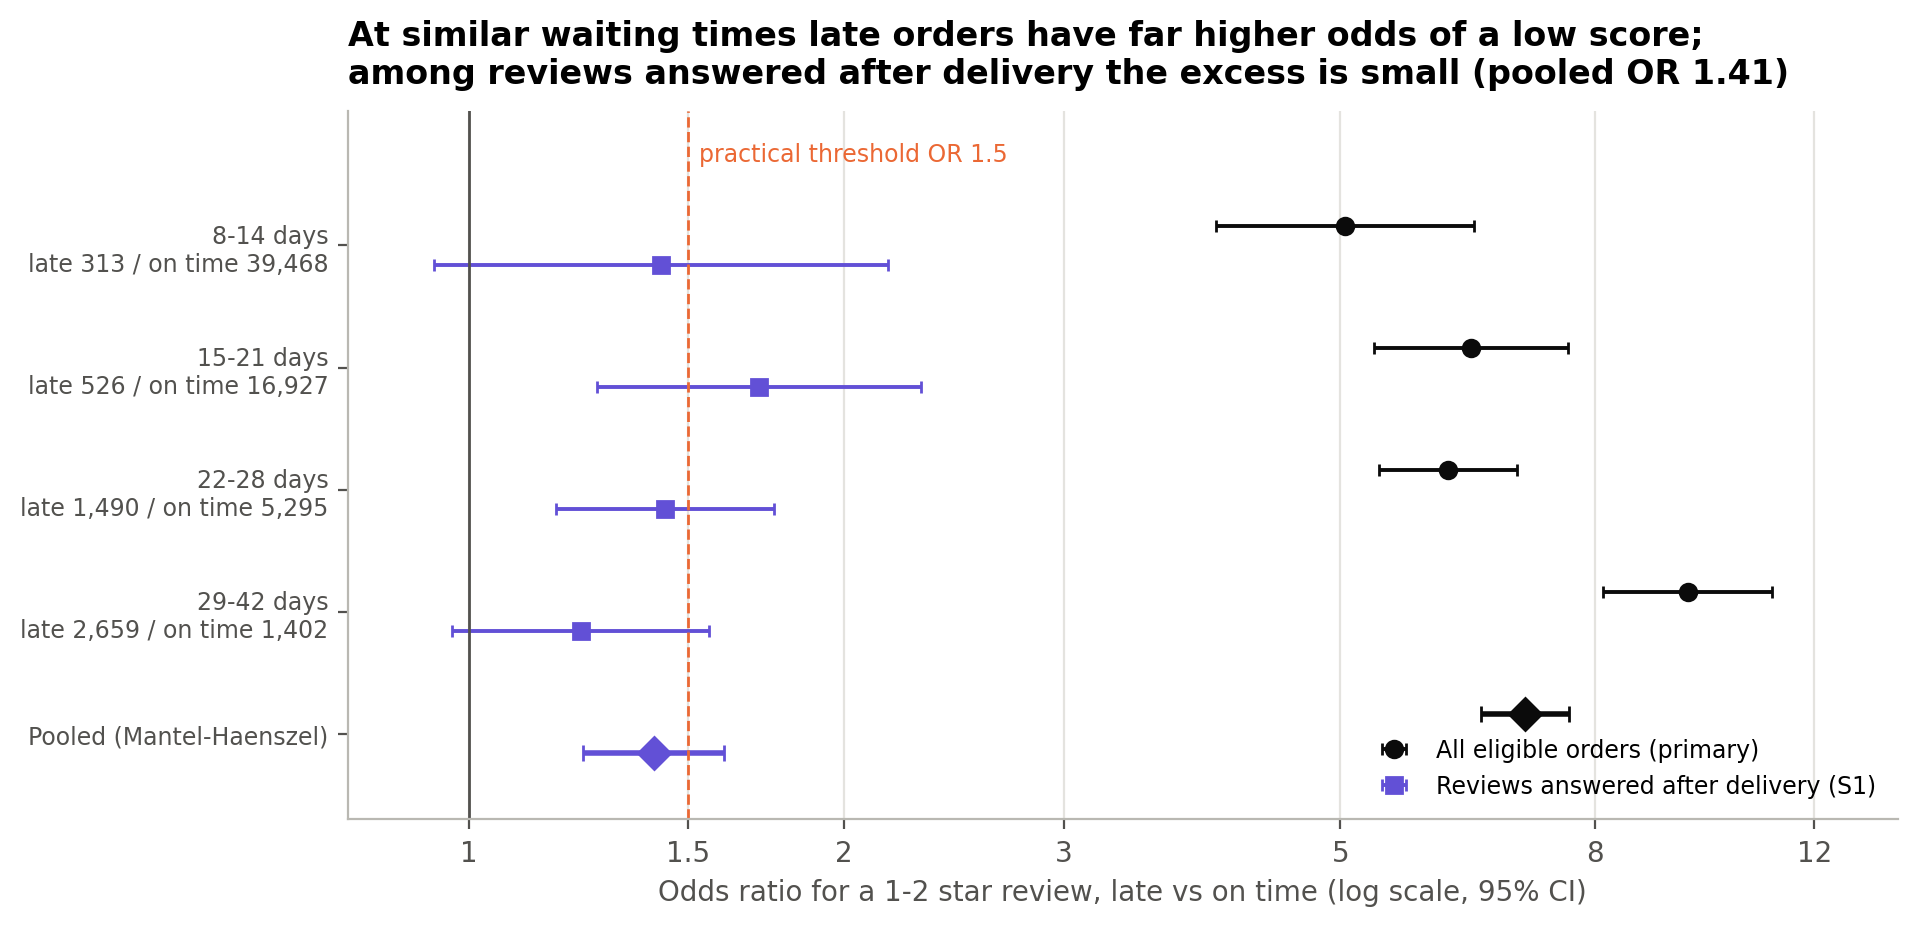

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.6))
rows = []
for lab, strata, res, colr, mk, off in [("All eligible orders (primary)", t3_strata, t3, INK, "o", 0.16),
                                        ("Reviews answered after delivery (S1)", t3_s1_strata, t3_s1, C_AFTER, "s", -0.16)]:
    e = strata[strata.eligible].reset_index(drop=True)
    y = np.arange(len(e))[::-1] + 1 + off
    ax.errorbar(e.odds_ratio, y, xerr=[e.odds_ratio - e.or_ci_low, e.or_ci_high - e.odds_ratio], fmt=mk, color=colr,
                ms=6, lw=1.4, capsize=2, label=lab)
    ax.errorbar([res["mh_odds_ratio"]], [off], xerr=[[res["mh_odds_ratio"] - res["ci_low"]], [res["ci_high"] - res["mh_odds_ratio"]]],
                fmt="D", color=colr, ms=8, lw=2, capsize=3)
    bands = list(e.band)
ax.axvline(1, color=INK2, lw=1)
ax.axvline(TH["T3_common_or"], color=C_LATE, lw=1, ls="--")
ax.text(TH["T3_common_or"] * 1.02, len(bands) + 0.75, "practical threshold OR 1.5", color=C_LATE, fontsize=8.5, va="center")
ax.set_xscale("log")
ticks = [1, 1.5, 2, 3, 5, 8, 12]
ax.xaxis.set_major_locator(FixedLocator(ticks)); ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(0.8, 14)
lab_y = list(np.arange(len(bands))[::-1] + 1) + [0]
n_lab = [f"{b} days\nlate {int(t3_strata.set_index('band').loc[b, 'n_late']):,} / on time {int(t3_strata.set_index('band').loc[b, 'n_on_time']):,}" for b in bands]
ax.set_yticks(lab_y, n_lab + ["Pooled (Mantel-Haenszel)"], fontsize=8.5)
ax.set_ylim(-0.7, len(bands) + 1.1)
ax.set_xlabel("Odds ratio for a 1-2 star review, late vs on time (log scale, 95% CI)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("At similar waiting times late orders have far higher odds of a low score;\n"
             f"among reviews answered after delivery the excess is small (pooled OR {t3_s1['mh_odds_ratio']:.2f})", pad=10)
fig.savefig(FIG / "P4_F2_stratified_odds_ratios.png"); plt.close(fig)
display(Image(filename=str(FIG / "P4_F2_stratified_odds_ratios.png")))

## Test 4: Among late orders, do longer delays go with lower scores?

- **Sample:** late orders only.
- **H₀:** Spearman's ρ between delay and review score is 0.
- **H₁:** ρ ≠ 0 (two-sided).
- **Delay measure:** `delay_calendar_days`, the number of whole calendar days between the promised date and the delivery date. This is the same basis as the calendar-day lateness rule D3, and 4A verified that `is_late = 1` exactly when it is above 0.
    - The timestamp-based `delay_days` also counts hours. A parcel delivered at 3 pm on the promised day would get +0.6 days although it is not late. It is used only as a labelled sensitivity check.

**Why Spearman?** Both variables are skewed, and the score is ordinal. Spearman's ρ correlates the **ranks**, so it needs no normality and picks up any consistently rising or falling relationship, not just a straight line. ρ ranges from −1 to +1, and negative values mean longer delays go with lower scores.

The p-value uses the usual t-approximation. The confidence interval uses a **BCa bootstrap** (5,000 resamples, seed 558), which needs no distributional assumption. A Fisher-z interval is shown as a cross-check. Correlation describes association only; it does not show that longer delays *cause* lower scores.

n = 6,353 late orders | rho = -0.402 | BCa 95% CI -0.424 to -0.380 (Fisher-z cross-check -0.423 to -0.381) | t = -35.04, df 6,351, p 5.15e-246
distinct delay values 113, distinct scores 5 (ties are handled by average ranks)


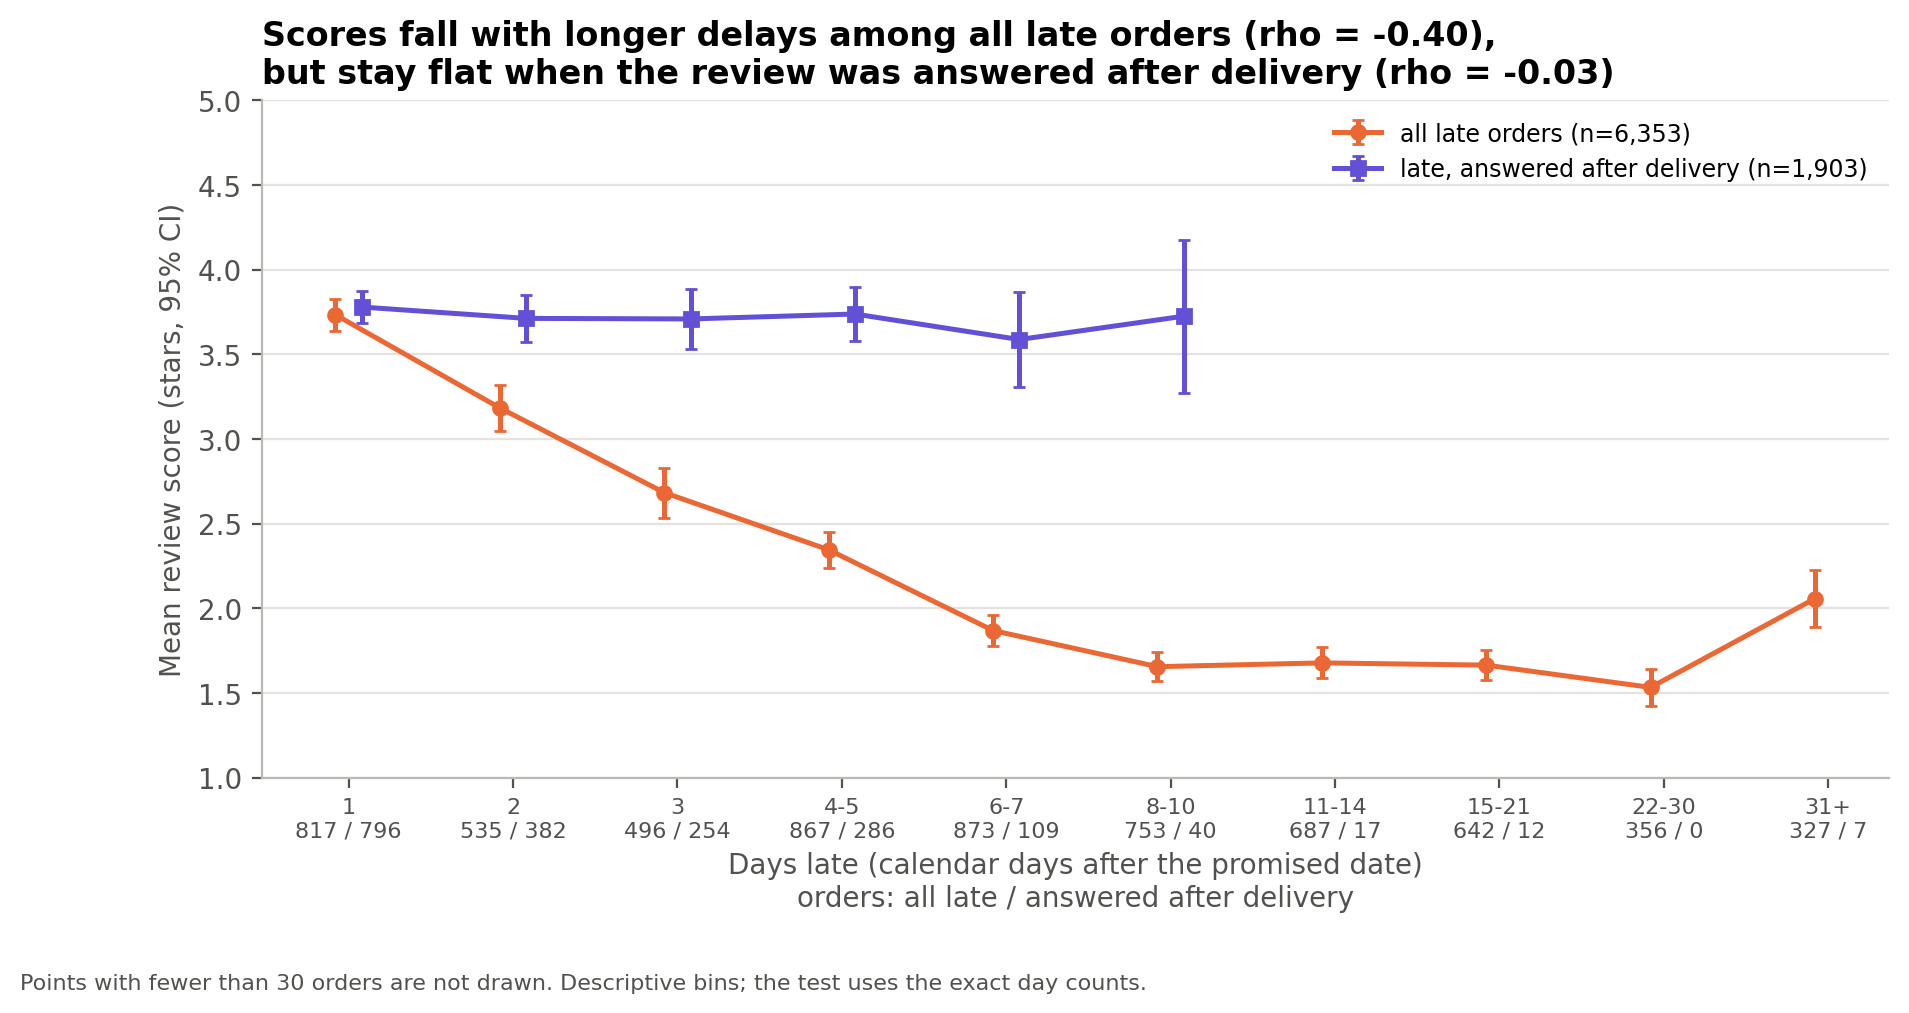

,delay_days_band,orders,mean,std,half,pct_low,scope
0,1,817,3.73,1.39,0.10,19.71,all late orders
1,2,535,3.18,1.59,0.13,34.21,all late orders
2,3,496,2.68,1.67,0.15,50.40,all late orders
3,4-5,867,2.35,1.60,0.11,60.21,all late orders
4,6-7,873,1.87,1.38,0.09,74.80,all late orders
5,8-10,753,1.66,1.20,0.09,80.48,all late orders
6,11-14,687,1.68,1.23,0.09,80.06,all late orders
7,15-21,642,1.67,1.17,0.09,81.00,all late orders
8,22-30,356,1.53,1.05,0.11,82.87,all late orders
9,31+,327,2.06,1.53,0.17,67.89,all late orders


In [11]:
t4 = test_spearman(f)
late = f[f.is_late == 1]
assert (late.delay_calendar_days >= 1).all() and len(late) == t4["n"]
print(f"n = {t4['n']:,} late orders | rho = {t4['rho']:.3f} | BCa 95% CI {t4['ci_low']:.3f} to {t4['ci_high']:.3f} "
      f"(Fisher-z cross-check {t4['fisher_ci_low']:.3f} to {t4['fisher_ci_high']:.3f}) | t = {t4['statistic']:.2f}, df {t4['df']:,}, p {fmt_p(t4['log10_p'])}")
print(f"distinct delay values {t4['distinct_x']}, distinct scores {t4['distinct_y']} (ties are handled by average ranks)")

DBINS = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30, np.inf]
DLAB = ["1", "2", "3", "4-5", "6-7", "8-10", "11-14", "15-21", "22-30", "31+"]
def delay_profile(df, scope):
    g = df.groupby(pd.cut(df.delay_calendar_days, DBINS, labels=DLAB), observed=False).review_score
    out = g.agg(["size", "mean", "std"]).reset_index()
    out["half"] = stats.t.ppf(0.975, out["size"] - 1) * out["std"] / np.sqrt(out["size"])
    out["pct_low"] = 100 * df.groupby(pd.cut(df.delay_calendar_days, DBINS, labels=DLAB), observed=False).low_score.mean().values
    out["scope"] = scope
    return out.rename(columns={"delay_calendar_days": "delay_days_band", "size": "orders"})
prof = pd.concat([delay_profile(late, "all late orders"), delay_profile(late[late.review_before_delivery == 0], "late, answered after delivery")],
                 ignore_index=True)

fig, ax = plt.subplots(figsize=(10.5, 4.4))
for scope, colr, mk, off in [("all late orders", C_LATE, "o", -0.08), ("late, answered after delivery", C_AFTER, "s", 0.08)]:
    d = prof[prof.scope == scope].reset_index(drop=True)
    ok = d.orders >= 30
    x = np.arange(len(d)) + off
    ax.errorbar(x[ok], d["mean"][ok], yerr=d["half"][ok], fmt=mk + "-", color=colr, ms=5, lw=1.8, capsize=2,
                label=f"{scope} (n={int(d.orders.sum()):,})")
pa = prof[prof.scope == "all late orders"].reset_index(drop=True)
pb = prof[prof.scope == "late, answered after delivery"].reset_index(drop=True)
ax.set_xticks(range(len(DLAB)), [f"{b}\n{int(n1):,} / {int(n2):,}" for b, n1, n2 in zip(DLAB, pa.orders, pb.orders)], fontsize=8)
ax.set(xlabel="Days late (calendar days after the promised date)\norders: all late / answered after delivery",
       ylabel="Mean review score (stars, 95% CI)", ylim=(1, 5))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=8.5)
t4_after_tmp = test_spearman(late[late.review_before_delivery == 0], seed=SEED)
ax.set_title(f"Scores fall with longer delays among all late orders (rho = {t4['rho']:.2f}),\n"
             f"but stay flat when the review was answered after delivery (rho = {t4_after_tmp['rho']:.2f})")
fig.text(0.01, -0.13, "Points with fewer than 30 orders are not drawn. Descriptive bins; the test uses the exact day counts.",
         fontsize=8, color=INK2)
fig.savefig(FIG / "P4_F3_delay_vs_score.png"); plt.close(fig)
display(Image(filename=str(FIG / "P4_F3_delay_vs_score.png")))
prof.round(2)

**Reading it.**

- **The correlation.** Among the 6,353 late orders, longer delays go with lower scores: **ρ = −0.40** (BCa 95% CI −0.42 to −0.38; t = −35.0, p ≈ 5 × 10⁻²⁴⁶). That is a moderate correlation, beyond the 0.10 practical threshold. The Fisher-z interval and the timestamp-based `delay_days` give practically the same values (ρ = −0.405).
- **The shape.** The figure shows the mean score falling from 3.7 stars at 1 day late to about 1.6 stars from 8 days late, then staying low; the small rise at 31+ days rests on 327 orders.
- **Review timing explains it.** Among the 1,903 late orders whose review was answered **after** delivery, the curve is **flat**: ρ = −0.03 (−0.08 to 0.01, p = 0.13). The longer a parcel is late, the more customers review it before it arrives. Those early reviews are very negative and produce the correlation.
- **Conclusion.** Once the parcel has arrived, how many days late it was is **not** associated with the score in these data; *whether* it was late still is (Tests 1–3, S1).

## Test 5: Are late orders more likely to carry a written message?

- **H₀:** P(message | late) = P(message | on time).
- **H₁:** they differ (two-sided).
- **Outcome:** `has_comment`, which is 1 when the review **message** contains real text. It is not the same as `has_any_text`, which also counts a title; that is used only as a sensitivity check.
- **Test:** two-proportion z-test, as in Test 2.

Writing a message is a **behaviour**: it tells us how often people choose to write, not whether what they write is positive or negative.

In [12]:
t5 = test_props(f, "has_comment")
tidy({**{k: t5[k] for k in ["n_late", "n_on_time", "k_late", "k_on_time", "p_late", "p_on_time", "risk_diff_pp", "ci_low",
                             "ci_high", "risk_ratio", "rr_ci_low", "rr_ci_high", "statistic", "min_expected_count"]},
      "p": fmt_p(t5["log10_p"])}, "Test 5")

,Test 5
n_late,6353
n_on_time,88943
k_late,3744
k_on_time,34952
p_late,0.5893
p_on_time,0.393
risk_diff_pp,19.6357
ci_low,18.3791
ci_high,20.8816
risk_ratio,1.4997


**Reading it.**

- **The rates.** **58.9%** of late orders carry a written message, against **39.3%** of on-time orders: +19.6 percentage points (95% CI 18.4 to 20.9; z = 30.8, p ≈ 4 × 10⁻²⁰⁸). The risk ratio is 1.50.
- **Counting titles too.** Using `has_any_text` gives almost the same difference, +19.0 points.
- **After delivery.** Among reviews answered after delivery, the difference shrinks to **+3.8 points** (1.6 to 6.1). That is still statistically detectable (p ≈ 0.0007), but **below the 5-point practical threshold**. Most of the extra writing on late orders comes from customers who were still waiting, as Phase 3's word analysis suggested ("não recebi": "I didn't receive it").
- **Caution.** Writing is a behaviour, not a sentiment measure.

## 4E. Correcting for multiple testing (Holm–Bonferroni)

**Why correct?** Each test at α = 0.05 has a 5% chance of a false alarm when its null hypothesis is actually true. Run five tests and the chance of **at least one** false alarm grows towards 23%. The Holm method keeps that **family-wise** chance at or below 5%.

**How it works**

1. Sort the five p-values from smallest to largest.
2. Multiply the smallest by 5, the next by 4, and so on down to 1.
3. Make the adjusted values non-decreasing, and cap them at 1.

It is uniformly more powerful than the plain Bonferroni correction (multiplying everything by 5). The correction uses the **five primary p-values only**; sensitivity analyses are reported separately. Each primary hypothesis has exactly one designated p-value:

| Test | Designated p-value |
|---|---|
| 1 | Welch |
| 2 | z |
| 3 | CMH |
| 4 | Spearman |
| 5 | z |

In [13]:
PRIMARY = [
    ("T1", "Mean review score, late vs on time", "mean(late) = mean(on time)", "mean(late) != mean(on time)", "Welch's t-test",
     t1, "t", "mean difference (stars, late - on time)", t1["mean_diff"], t1["ci_low"], t1["ci_high"], TH["T1_mean_diff_stars"], -1),
    ("T2", "Share of 1-2 star reviews, late vs on time", "P(low|late) = P(low|on time)", "P(low|late) != P(low|on time)",
     "two-proportion z-test", t2, "z", "risk difference (pp, late - on time)", t2["risk_diff_pp"], t2["ci_low"], t2["ci_high"],
     TH["T2_risk_diff_pp"], +1),
    ("T3", "Low score, late vs on time, within waiting-time bands", "common OR = 1 across eligible waiting bands",
     "common OR != 1", "Cochran-Mantel-Haenszel", t3, "chi2", "Mantel-Haenszel common odds ratio", t3["mh_odds_ratio"],
     t3["ci_low"], t3["ci_high"], TH["T3_common_or"], +1),
    ("T4", "Delay length vs review score among late orders", "Spearman rho = 0", "rho != 0", "Spearman rank correlation",
     t4, "t", "Spearman rho", t4["rho"], t4["ci_low"], t4["ci_high"], TH["T4_abs_spearman_rho"], 0),
    ("T5", "Share with a written message, late vs on time", "P(comment|late) = P(comment|on time)",
     "P(comment|late) != P(comment|on time)", "two-proportion z-test", t5, "z", "risk difference (pp, late - on time)",
     t5["risk_diff_pp"], t5["ci_low"], t5["ci_high"], TH["T5_risk_diff_pp"], 0),
]
l10 = np.array([r[5]["log10_p"] for r in PRIMARY])
l10_holm = holm_log10(l10)
# cross-check against statsmodels wherever the p-values are representable
ok = l10 > -290
if ok.any():
    sm_adj = multipletests(10 ** l10[ok], alpha=0.05, method="holm")[1]
    assert np.allclose(np.log10(sm_adj), l10_holm[ok]), "Holm (log scale) disagrees with statsmodels"
primary = pd.DataFrame([{
    "test": tid, "question": q, "H0": h0, "H1": h1, "sidedness": "two-sided", "method": meth,
    "n": int(res["n"]), "n_late": int(res.get("n_late", res["n"])), "n_on_time": int(res.get("n_on_time", 0)),
    "statistic_name": sn, "statistic": res["statistic"], "df": res.get("df", np.nan),
    "p_raw": p_of(lr), "log10_p_raw": lr, "p_raw_display": fmt_p(lr),
    "p_holm": p_of(lh), "log10_p_holm": lh, "p_holm_display": fmt_p(lh), "reject_H0_holm_alpha_0.05": bool(lh < math.log10(0.05)),
    "effect": eff, "estimate": est, "ci_low": lo, "ci_high": hi, "practical_threshold": thr,
    "practical_verdict": verdict(est, lo, hi, thr, dirn)}
    for (tid, q, h0, h1, meth, res, sn, eff, est, lo, hi, thr, dirn), lr, lh in zip(PRIMARY, l10, l10_holm)])
primary.loc[primary.test == "T4", "n_on_time"] = 0
primary[["test", "method", "n", "statistic_name", "statistic", "p_raw_display", "p_holm_display", "reject_H0_holm_alpha_0.05",
         "effect", "estimate", "ci_low", "ci_high", "practical_verdict"]].round(4)

,test,method,n,statistic_name,statistic,p_raw_display,p_holm_display,reject_H0_holm_alpha_0.05,effect,estimate,ci_low,ci_high,practical_verdict
0,T1,Welch's t-test,95296,t,-100.4146,< 1e-300 (log10 p = -1348),< 1e-300 (log10 p = -1347),True,"mean difference (stars, late - on time)",-2.0186,-2.0580,-1.9792,clearly important (whole CI beyond threshold)
1,T2,two-proportion z-test,95296,z,122.4734,< 1e-300 (log10 p = -3259),< 1e-300 (log10 p = -3259),True,"risk difference (pp, late - on time)",53.1167,51.9030,54.3152,clearly important (whole CI beyond threshold)
2,T3,Cochran-Mantel-Haenszel,68080,chi2,2470.9789,< 1e-300 (log10 p = -538),< 1e-300 (log10 p = -538),True,Mantel-Haenszel common odds ratio,7.0310,6.4800,7.6288,clearly important (whole CI beyond threshold)
3,T4,Spearman rank correlation,6353,t,-35.0351,5.15e-246,1.03e-245,True,Spearman rho,-0.4025,-0.4244,-0.3796,clearly important (whole CI beyond threshold)
4,T5,two-proportion z-test,95296,z,30.7885,3.74e-208,3.74e-208,True,"risk difference (pp, late - on time)",19.6357,18.3791,20.8816,clearly important (whole CI beyond threshold)


**Reading it.**

- **Holm changes no decision.** The adjusted p-values are at most 5 times the raw ones: log₁₀ goes up by at most 0.7. Every raw p-value is below 10⁻²⁰⁰, so **all five null hypotheses are rejected** at a family-wise α of 0.05.
- **Size is a separate question.** With 95,000 orders, rejection was expected for almost any real difference. All five **primary** effects are also **clearly important**: each whole CI is beyond its pre-set threshold.
- **The rest of this notebook** therefore focuses on effect sizes and on whether they survive the sensitivity analyses.

## 4F. Sensitivity analyses

Each test is rerun on the four pre-specified sensitivity samples (S1–S4), plus the test-specific checks listed in the plan. These are **not** extra hypotheses, so they are not Holm-corrected. Their job is to show whether the **direction and size** of each effect hold up when the most important doubts are removed:

- reviews written before the parcel arrived;
- repeat customers;
- shared review records.

The primary sample is never replaced by a sensitivity sample.

In [14]:
sens_rows = []
def add(sample, test, label, res, effect, est, lo, hi, extra=""):
    sens_rows.append({"sample": sample, "test": test, "analysis": label, "n": int(res["n"]),
                      "n_late": int(res.get("n_late", res["n"])), "n_on_time": int(res.get("n_on_time", 0)),
                      "statistic": res["statistic"], "log10_p": res["log10_p"], "p_display": fmt_p(res["log10_p"]),
                      "effect": effect, "estimate": est, "ci_low": lo, "ci_high": hi, "note": extra})

res_by_sample, strata_by_sample = {}, {"Primary": t3_strata, "S1 after delivery": t3_s1_strata}
for name, df in S.items():
    r1 = t1 if name == "Primary" else test_welch(df)
    rm = t1_mwu if name == "Primary" else test_mwu(df)
    r2 = t2 if name == "Primary" else test_props(df, "low_score")
    if name == "Primary": r3 = t3
    elif name == "S1 after delivery": r3 = t3_s1
    else: r3, strata_by_sample[name] = test_cmh(df)
    r4 = t4 if name == "Primary" else test_spearman(df)
    r5 = t5 if name == "Primary" else test_props(df, "has_comment")
    r5b = test_props(df, "has_any_text")
    res_by_sample[name] = {"T1": r1, "MWU": rm, "T2": r2, "T3": r3, "T4": r4, "T5": r5, "T5b": r5b}
    tag = "primary analysis" if name == "Primary" else "sensitivity"
    add(name, "T1", f"Welch t ({tag})", r1, "mean difference (stars)", r1["mean_diff"], r1["ci_low"], r1["ci_high"],
        f"Hedges g {r1['hedges_g']:.3f} ({r1['g_ci_low']:.3f} to {r1['g_ci_high']:.3f}); means {r1['mean_late']:.3f} vs {r1['mean_on_time']:.3f}")
    add(name, "T1", "Mann-Whitney U (sensitivity)", rm, "P(late score > on-time score), ties half", rm["prob_superiority"],
        rm["ps_ci_low"], rm["ps_ci_high"], f"rank-biserial r {rm['rank_biserial']:.3f}; bootstrap CI, seed {SEED}")
    add(name, "T2", f"two-proportion z ({tag})", r2, "risk difference, low score (pp)", r2["risk_diff_pp"], r2["ci_low"], r2["ci_high"],
        f"{100*r2['p_late']:.1f}% vs {100*r2['p_on_time']:.1f}%; RR {r2['risk_ratio']:.2f} ({r2['rr_ci_low']:.2f} to {r2['rr_ci_high']:.2f})")
    add(name, "T3", f"CMH ({tag})", r3, "Mantel-Haenszel common OR", r3["mh_odds_ratio"], r3["ci_low"], r3["ci_high"],
        f"bands {r3['bands_used']}; excluded {r3['orders_excluded']:,} orders; crude OR {r3['crude_odds_ratio']:.2f}; "
        f"Breslow-Day p {fmt_p(r3['breslow_day_log10_p'])}; stratum ORs {r3['stratum_or_min']:.2f}-{r3['stratum_or_max']:.2f}")
    add(name, "T4", f"Spearman ({tag})", r4, "Spearman rho (late orders)", r4["rho"], r4["ci_low"], r4["ci_high"],
        f"BCa bootstrap CI, {B} resamples, seed {SEED}")
    add(name, "T5", f"two-proportion z ({tag})", r5, "risk difference, has_comment (pp)", r5["risk_diff_pp"], r5["ci_low"], r5["ci_high"],
        f"{100*r5['p_late']:.1f}% vs {100*r5['p_on_time']:.1f}%")
    add(name, "T5", "has_any_text instead of has_comment (sensitivity)", r5b, "risk difference, has_any_text (pp)",
        r5b["risk_diff_pp"], r5b["ci_low"], r5b["ci_high"], f"{100*r5b['p_late']:.1f}% vs {100*r5b['p_on_time']:.1f}%")

# test-specific checks on the primary sample
t3_fine, t3_fine_strata = test_cmh(f, PLAN["fine_wait_bins"],
                                   [f"{a:g}-{b:g}" for a, b in zip(PLAN["fine_wait_bins"][:-1], PLAN["fine_wait_bins"][1:])])
add("Primary", "T3", "CMH with half-week strata, 7-42 days (sensitivity)", t3_fine, "Mantel-Haenszel common OR",
    t3_fine["mh_odds_ratio"], t3_fine["ci_low"], t3_fine["ci_high"],
    f"bands {t3_fine['bands_used']}; excluded {t3_fine['orders_excluded']:,} orders within 7-42 days; "
    f"Breslow-Day p {fmt_p(t3_fine['breslow_day_log10_p'])}; stratum ORs {t3_fine['stratum_or_min']:.2f}-{t3_fine['stratum_or_max']:.2f}")
strata_by_sample["Primary, half-week strata"] = t3_fine_strata
t4_ts = test_spearman(f, x="delay_days")
add("Primary", "T4", "Spearman with timestamp delay_days (sensitivity)", t4_ts, "Spearman rho (late orders)", t4_ts["rho"],
    t4_ts["ci_low"], t4_ts["ci_high"], "delay in fractional days from timestamps; late defined by the calendar rule as before")
t4_s1 = res_by_sample["S1 after delivery"]["T4"]

sens = pd.DataFrame(sens_rows)
sens.insert(0, "role", np.where(sens.analysis.str.contains("primary analysis"), "primary (Holm family)", "sensitivity (not corrected)"))
sens[["role", "sample", "test", "analysis", "n", "estimate", "ci_low", "ci_high", "p_display"]].round(3)

,role,sample,test,analysis,n,estimate,ci_low,ci_high,p_display
0,primary (Holm family),Primary,T1,Welch t (primary analysis),95296,-2.019,-2.058,-1.979,< 1e-300 (log10 p = -1348)
1,sensitivity (not corrected),Primary,T1,Mann-Whitney U (sensitivity),95296,0.181,0.175,0.187,< 1e-300 (log10 p = -2007)
2,primary (Holm family),Primary,T2,two-proportion z (primary analysis),95296,53.117,51.903,54.315,< 1e-300 (log10 p = -3259)
3,primary (Holm family),Primary,T3,CMH (primary analysis),68080,7.031,6.480,7.629,< 1e-300 (log10 p = -538)
4,primary (Holm family),Primary,T4,Spearman (primary analysis),6353,-0.402,-0.424,-0.380,5.15e-246
5,primary (Holm family),Primary,T5,two-proportion z (primary analysis),95296,19.636,18.379,20.882,3.74e-208
6,sensitivity (not corrected),Primary,T5,has_any_text instead of has_comment (sensitivity),95296,18.971,17.719,20.212,4.72e-192
7,sensitivity (not corrected),S1 after delivery,T1,Welch t (sensitivity),90672,-0.569,-0.632,-0.506,4.45e-65
8,sensitivity (not corrected),S1 after delivery,T1,Mann-Whitney U (sensitivity),90672,0.376,0.364,0.388,3.61e-101
9,sensitivity (not corrected),S1 after delivery,T2,two-proportion z (sensitivity),90672,10.157,8.433,12.004,8.46e-51


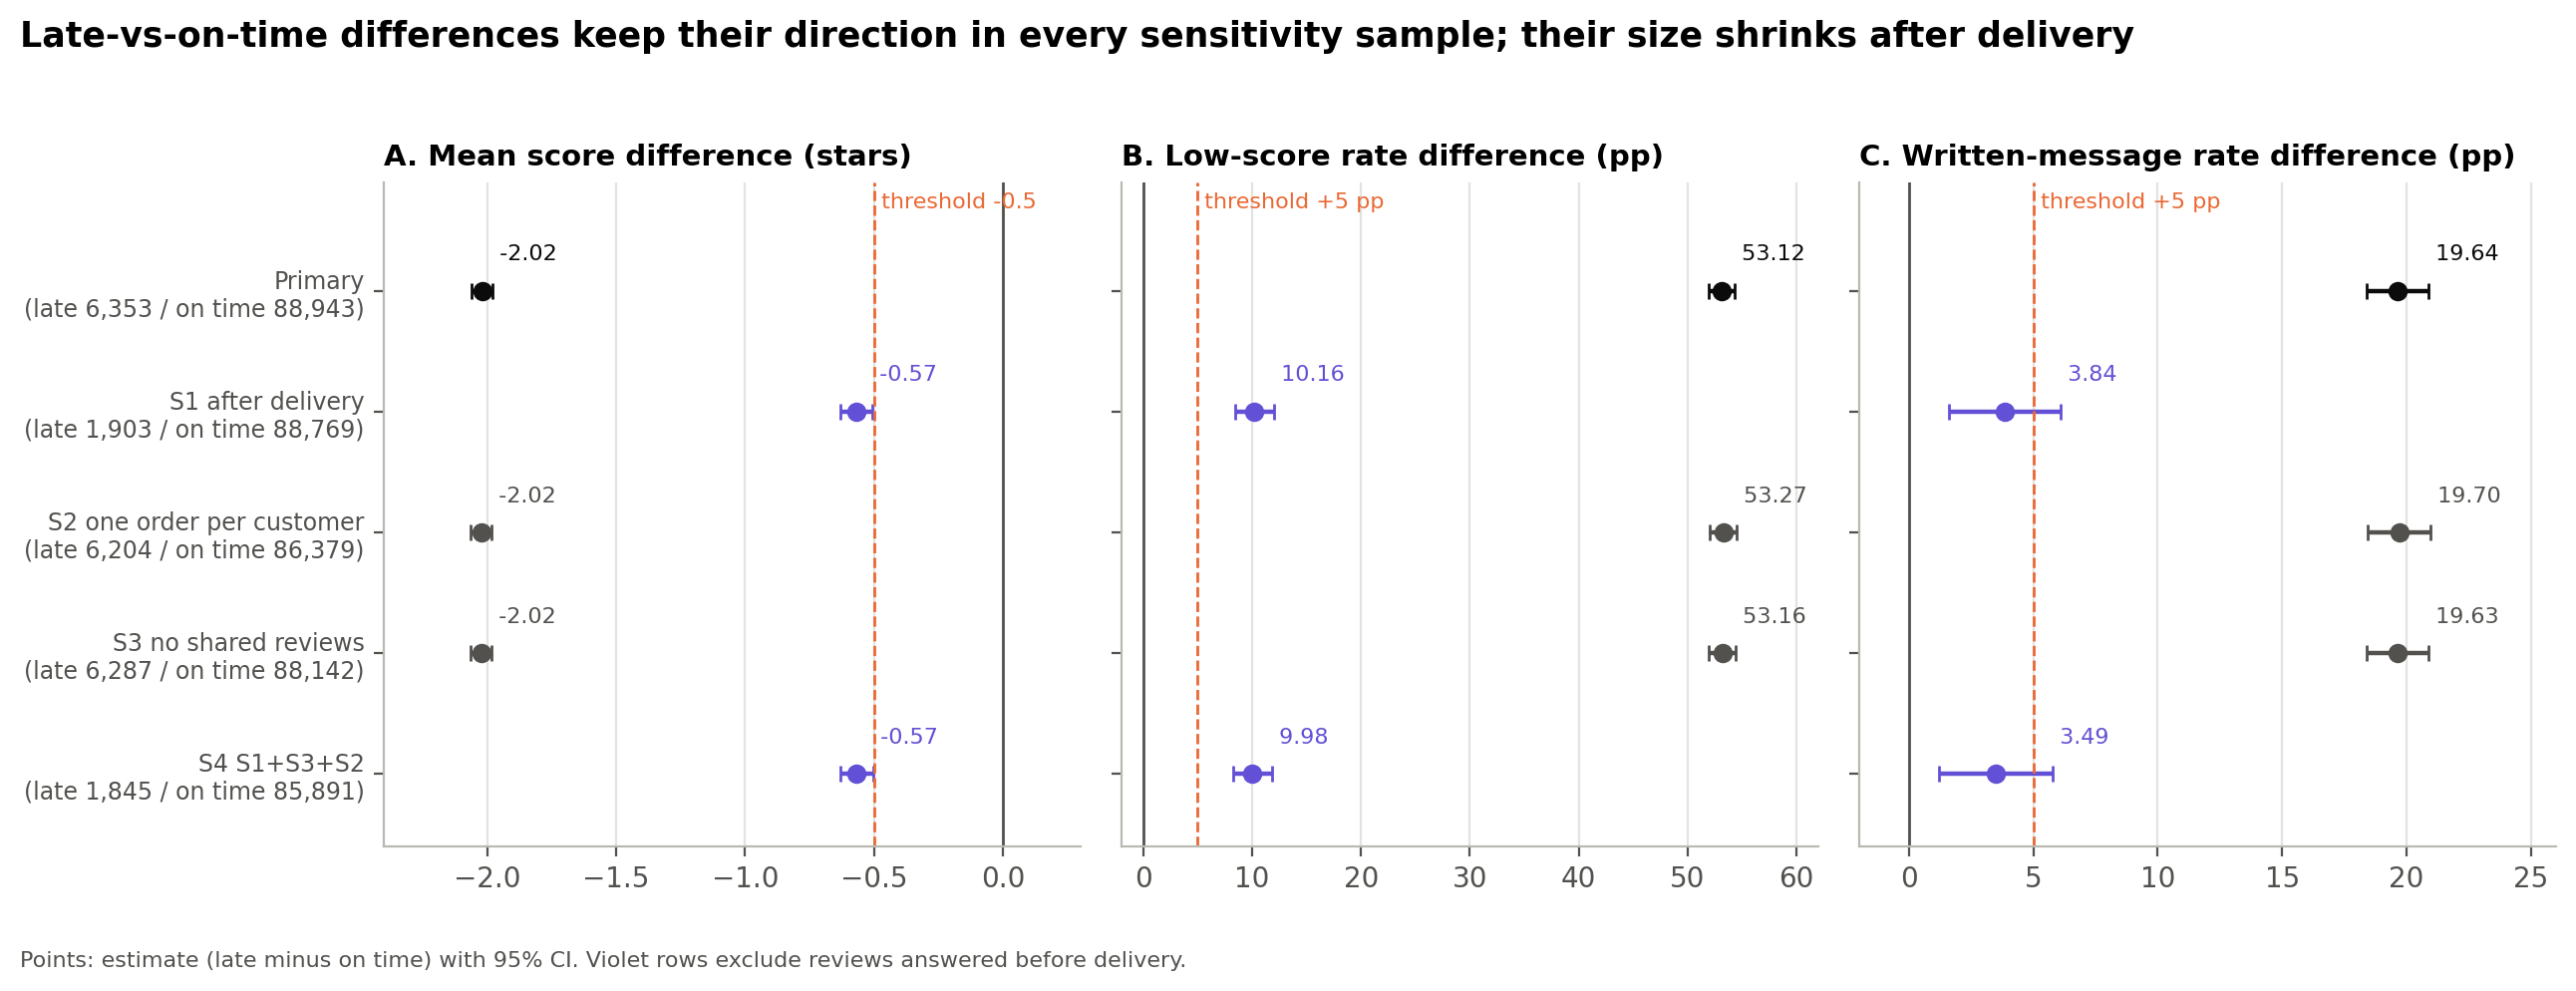

In [15]:
# Forest plot: the three late-vs-on-time effects in every sample
order = list(S.keys())
panels = [("T1", "Welch t", "A. Mean score difference (stars)", -TH["T1_mean_diff_stars"], "threshold -0.5"),
          ("T2", "two-proportion z", "B. Low-score rate difference (pp)", TH["T2_risk_diff_pp"], "threshold +5 pp"),
          ("T5", "two-proportion z", "C. Written-message rate difference (pp)", TH["T5_risk_diff_pp"], "threshold +5 pp")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, (test, meth, ttl, thr, thr_lab) in zip(axes, panels):
    d = sens[(sens.test == test) & sens.analysis.str.startswith(meth)].set_index("sample").reindex(order)
    y = np.arange(len(order))[::-1]
    cols = [INK if s == "Primary" else (C_AFTER if s.startswith("S1") or s.startswith("S4") else INK2) for s in order]
    for yi, (_, r), c in zip(y, d.iterrows(), cols):
        ax.errorbar(r.estimate, yi, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o", color=c, ms=6, capsize=3, lw=1.6)
        ax.text(r.ci_high, yi + 0.22, f" {r.estimate:.2f}", fontsize=8, color=c, va="bottom")
    ax.axvline(0, color=INK2, lw=1)
    ax.axvline(thr, color=C_LATE, lw=1, ls="--")
    ax.text(thr, len(order) - 0.35, f" {thr_lab}", color=C_LATE, fontsize=8, va="bottom")
    ax.set_title(ttl, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.6, len(order) - 0.1)
axes[0].set_yticks(np.arange(len(order))[::-1], [f"{s}\n(late {int(S[s].is_late.sum()):,} / on time {int((S[s].is_late == 0).sum()):,})" for s in order], fontsize=8.5)
axes[0].set_xlim(-2.4, 0.3); axes[1].set_xlim(-2, 62); axes[2].set_xlim(-2, 26)
fig.suptitle("Late-vs-on-time differences keep their direction in every sensitivity sample; their size shrinks after delivery",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", y=1.03)
fig.text(0.01, -0.05, "Points: estimate (late minus on time) with 95% CI. Violet rows exclude reviews answered before delivery.",
         fontsize=8, color=INK2)
fig.tight_layout()
fig.savefig(FIG / "P4_F1_effects_by_sample.png"); plt.close(fig)
display(Image(filename=str(FIG / "P4_F1_effects_by_sample.png")))

**Reading it: the sensitivity analyses.**

- **S2 and S3 change almost nothing.** Keeping one order per customer (S2, 2,713 orders removed) or dropping shared review records (S3, 867 orders removed) leaves every estimate essentially unchanged:
    - the mean difference stays −2.02;
    - the low-score gap stays 53.2–53.3 points;
    - the CMH OR stays 7.04–7.11;
    - ρ stays −0.40 to −0.41;
    - the comment gap stays 19.6–19.7 points.
    - So repeat customers and shared reviews are a real independence concern, but they are not driving the results.
- **S1 changes the size of every effect a lot, but never its direction.** Keeping only reviews answered after delivery (S1):
    - **Test 1:** the mean difference shrinks to **−0.57 stars** (−0.63 to −0.51). That is still beyond the 0.5-star threshold, but only just.
    - **Test 2:** the low-score gap shrinks to **+10.2 points** (8.4 to 12.0), 19.4% against 9.2% (risk ratio 2.1). That is still clearly important.
    - **Test 3:** the stratified OR shrinks to **1.41**, below the 1.5 threshold.
    - **Test 4:** the delay-length correlation **disappears** (ρ = −0.03, CI includes 0).
    - **Test 5:** the comment gap shrinks to **+3.8 points**, below the 5-point threshold.
- **S4 (all three restrictions together)** gives almost the same results as S1.
- **Why S1 matters.** 70% of late orders were reviewed before the parcel arrived, against 0.2% of on-time orders. Those reviews are **valid feedback**, about waiting past the promise rather than about the product received, so they stay in the primary analysis. But they make the primary late-versus-on-time gap a mixture of "I am still waiting" and "it arrived late". S1 isolates the second.

## 4F-2. Comparison with alternative tests

The course guidelines ask which other tests we considered for each question, and why we did not use them. To show that **no conclusion depends on the choice of test**, each primary test is compared with one or two reasonable alternatives on the **same primary sample**.

These comparisons are not new hypotheses. They are not part of the Holm family, and they do not replace any primary result.

| Primary test | Alternatives compared | Why the alternative is not the primary test |
|---|---|---|
| T1 Welch t | Student's t (pooled variance); Mann–Whitney U (from 4F) | Student's t assumes equal variances, but the variance ratio is 1.88. Mann–Whitney answers a different question (stochastic ordering, not means), so it is kept as the ordinal check. |
| T2 z-test | Pearson χ² with and without Yates' correction; Fisher's exact test | χ² without correction is mathematically identical to z²; the z form gives a signed risk difference with a CI. Yates' correction and Fisher's exact test are designed for small counts, and every expected count here is above 800. |
| T3 CMH | CMH with continuity correction; logistic regression (low score ~ late + waiting band) | The continuity correction matters only for small strata. Logistic regression adds model assumptions (a common OR on the logit scale, with band effects added on) and its Wald test can behave poorly; CMH needs no model and is the standard stratified test for 2 × 2 × K tables. |
| T4 Spearman | Kendall's τ-b; Pearson r | Pearson assumes a linear relationship on an interval scale, and the delays have a long tail (up to 188 days). Kendall's τ-b is valid too, but its scale is smaller and harder to compare with conventional thresholds. |
| T5 z-test | Pearson χ² with Yates' correction; Fisher's exact test | Same reasons as T2. |

Where an alternative's p-value is below 10⁻³⁰⁰ and cannot be computed on a log scale (Fisher's exact test, Kendall's τ), it is shown as \"< 1e-300\". It is not zero; it is just too small to represent.

In [16]:
import statsmodels.formula.api as smf
ALT = []
def alt(test, primary, alternative, stat_name, stat, df_, l10, effect, est, lo=np.nan, hi=np.nan, why=""):
    p_disp = fmt_p(l10) if np.isfinite(l10) else "< 1e-300 (underflow; not representable)"
    ALT.append({"test": test, "primary_test": primary, "alternative": alternative, "statistic_name": stat_name, "statistic": stat,
                "df": df_, "log10_p": l10, "p_display": p_disp, "reject_at_0.05": bool((not np.isfinite(l10)) or l10 < math.log10(0.05)),
                "effect": effect, "estimate": est, "ci_low": lo, "ci_high": hi, "why_not_primary": why})
def log10_or_underflow(p):
    return math.log10(p) if p > 1e-300 else -np.inf

# T1
x1, x0 = split(f, "review_score")
st_ = stats.ttest_ind(x1, x0, equal_var=True); dfs = len(x1) + len(x0) - 2
sp_ = math.sqrt(((len(x1) - 1) * x1.var(ddof=1) + (len(x0) - 1) * x0.var(ddof=1)) / dfs); se_s = sp_ * math.sqrt(1 / len(x1) + 1 / len(x0))
qs = stats.t.ppf(0.975, dfs)
bf_1, bf_p1 = stats.levene(x1, x0, center="median")
alt("T1", "Welch t", "Student t (pooled variance)", "t", float(st_.statistic), dfs, log10p_t2(float(st_.statistic), dfs),
    "mean difference (stars)", t1["mean_diff"], t1["mean_diff"] - qs * se_s, t1["mean_diff"] + qs * se_s,
    f"assumes equal variances; variance ratio is {t1['variance_ratio']:.2f} (Brown-Forsythe F = {bf_1:.2f}, p = {bf_p1:.2e})")
alt("T1", "Welch t", "Mann-Whitney U (tie-corrected)", "z", t1_mwu["statistic"], np.nan, t1_mwu["log10_p"],
    "P(late > on time), ties half", t1_mwu["prob_superiority"], t1_mwu["ps_ci_low"], t1_mwu["ps_ci_high"],
    "tests stochastic ordering, not the mean; kept as the ordinal check")

# T2 and T5
for tid, col, res in [("T2", "low_score", t2), ("T5", "has_comment", t5)]:
    tab = np.array([[res["k_late"], res["n_late"] - res["k_late"]], [res["k_on_time"], res["n_on_time"] - res["k_on_time"]]])
    c0 = stats.chi2_contingency(tab, correction=False); c1 = stats.chi2_contingency(tab, correction=True)
    assert math.isclose(c0.statistic, res["statistic"] ** 2, rel_tol=1e-9), "chi-square should equal z squared"
    fe = stats.fisher_exact(tab)
    if tid == "T2":
        alt(tid, "two-proportion z", "Pearson chi-square, no correction", "chi2", float(c0.statistic), 1, log10p_chi2(float(c0.statistic), 1),
            "identical to z squared", res["risk_diff_pp"], res["ci_low"], res["ci_high"], "same test as z (chi2 = z^2); z gives a signed effect")
    alt(tid, "two-proportion z", "Pearson chi-square, Yates correction", "chi2", float(c1.statistic), 1, log10p_chi2(float(c1.statistic), 1),
        "risk difference (pp)", res["risk_diff_pp"], res["ci_low"], res["ci_high"], "correction is meant for small expected counts")
    alt(tid, "two-proportion z", "Fisher exact test", "sample odds ratio", float(fe.statistic), np.nan, log10_or_underflow(float(fe.pvalue)),
        "odds ratio", float(fe.statistic), res["or_ci_low"], res["or_ci_high"], "exact test for small counts; unnecessary with expected counts >= 800")

# T3
band = wait_band(f)
elig_df = f[band.isin(t3["bands_used"].split(", "))].assign(band=band.astype(str))
tables = np.array([[[((g.is_late == 1) & (g.low_score == 1)).sum(), ((g.is_late == 1) & (g.low_score == 0)).sum()],
                    [((g.is_late == 0) & (g.low_score == 1)).sum(), ((g.is_late == 0) & (g.low_score == 0)).sum()]]
                   for _, g in elig_df.groupby("band")], float).transpose(1, 2, 0)
cc = StratifiedTable(tables).test_null_odds(correction=True)
alt("T3", "CMH", "CMH with continuity correction", "chi2", float(cc.statistic), 1, log10p_chi2(float(cc.statistic), 1),
    "Mantel-Haenszel common OR", t3["mh_odds_ratio"], t3["ci_low"], t3["ci_high"], "correction only matters for small strata")
lr = smf.logit("low_score ~ is_late + C(band)", data=elig_df).fit(disp=False)
z_lr = float(lr.tvalues["is_late"]); ci_lr = np.exp(lr.conf_int().loc["is_late"])
alt("T3", "CMH", "logistic regression: low_score ~ is_late + C(wait band)", "Wald z", z_lr, np.nan, log10p_norm2(z_lr),
    "adjusted OR for late", float(np.exp(lr.params["is_late"])), float(ci_lr[0]), float(ci_lr[1]),
    "model-based (common logit OR, additive band effects); Wald test; CMH needs no model")

# T4
xs, ys = late.delay_calendar_days.to_numpy(float), late.review_score.to_numpy(float)
kt = stats.kendalltau(xs, ys)               # tau-b, ties handled
pr = stats.pearsonr(xs, ys); r = float(pr.statistic); n_ = len(xs)
t_r = r * math.sqrt((n_ - 2) / (1 - r * r)); zr, ser = math.atanh(r), 1 / math.sqrt(n_ - 3)
alt("T4", "Spearman", "Kendall tau-b", "tau-b", float(kt.statistic), np.nan, log10_or_underflow(float(kt.pvalue)),
    "Kendall tau-b", float(kt.statistic), why="valid rank alternative; different (smaller) scale than rho")
alt("T4", "Spearman", "Pearson r on raw values", "t", t_r, n_ - 2, log10p_t2(t_r, n_ - 2), "Pearson r", r,
    math.tanh(zr - 1.96 * ser), math.tanh(zr + 1.96 * ser), "assumes a linear relation on an interval scale; delays have a long tail")

alternatives = pd.DataFrame(ALT)
prim_sign = {"T1": np.sign(t1["mean_diff"]), "T2": 1, "T3": 1, "T4": np.sign(t4["rho"]), "T5": 1}
def same_direction(r):
    if r.effect.startswith("P(late"): return np.sign(r.estimate - 0.5) == prim_sign[r.test]
    if "odds" in r.effect.lower() or r.effect.startswith("adjusted OR") or r.effect.startswith("Mantel"): return np.sign(math.log(r.estimate)) == prim_sign[r.test]
    return np.sign(r.estimate) == prim_sign[r.test]
alternatives["same_direction_as_primary"] = alternatives.apply(same_direction, axis=1)
alternatives["agrees_with_primary"] = alternatives.same_direction_as_primary & alternatives["reject_at_0.05"]
alternatives.to_csv(OUT4 / "alternative_tests_comparison.csv", index=False)
alternatives[["test", "alternative", "statistic_name", "statistic", "p_display", "effect", "estimate", "ci_low", "ci_high",
              "agrees_with_primary"]].round(4)


,test,alternative,statistic_name,statistic,p_display,effect,estimate,ci_low,ci_high,agrees_with_primary
0,T1,Student t (pooled variance),t,-131.5778,< 1e-300 (log10 p = -3457),mean difference (stars),-2.0186,-2.0487,-1.9885,True
1,T1,Mann-Whitney U (tie-corrected),z,-96.0838,< 1e-300 (log10 p = -2007),"P(late > on time), ties half",0.1813,0.1752,0.1871,True
2,T2,"Pearson chi-square, no correction",chi2,14999.7247,< 1e-300 (log10 p = -3259),identical to z squared,53.1167,51.9030,54.3152,True
3,T2,"Pearson chi-square, Yates correction",chi2,14994.9625,< 1e-300 (log10 p = -3258),risk difference (pp),53.1167,51.9030,54.3152,True
4,T2,Fisher exact test,sample odds ratio,16.2618,< 1e-300 (underflow; not representable),odds ratio,16.2618,15.3824,17.1915,True
5,T5,"Pearson chi-square, Yates correction",chi2,947.1154,5.62e-208,risk difference (pp),19.6357,18.3791,20.8816,True
6,T5,Fisher exact test,sample odds ratio,2.2167,1.38e-203,odds ratio,2.2167,2.1049,2.3345,True
7,T3,CMH with continuity correction,chi2,2468.7723,< 1e-300 (log10 p = -538),Mantel-Haenszel common OR,7.0310,6.4800,7.6288,True
8,T3,logistic regression: low_score ~ is_late + C(wait band),Wald z,47.0881,< 1e-300 (log10 p = -483),adjusted OR for late,6.8135,6.2904,7.3800,True
9,T4,Kendall tau-b,tau-b,-0.3122,5.80e-226,Kendall tau-b,-0.3122,NaN,NaN,True


**Reading it.** Every alternative agrees with its primary test in direction and decision.

- **T1.** Student's t gives the same difference, −2.02 stars, with a slightly narrower CI because it pools the variances. Mann–Whitney gives P(late > on time) = 0.18.
- **T2 and T5.** χ² without correction equals z² exactly (14,999.7 = 122.47²). Yates' correction barely changes the statistic, because the counts are large. Fisher's exact test agrees; its p-value is too small to represent in T2 and is 1.4 × 10⁻²⁰³ in T5.
- **T3.** The continuity-corrected CMH gives χ² = 2,468.8 against 2,471.0. Logistic regression with waiting-band dummies gives an adjusted OR of **6.81** (6.29 to 7.38), close to the Mantel–Haenszel 7.03.
- **T4.** Kendall's τ-b = −0.31 tells the same story as ρ = −0.40, on its usual smaller scale.
    - Pearson's r is only **−0.15**. A straight line fits this relationship badly: scores fall over the first week of delay and then level off (figure P4_F3), and the 188-day tail pulls a linear fit.
    - That is exactly why a rank correlation was chosen.

## 4G. Assumption checks

The table below records, for each test, every assumption or validity condition that was checked, the value found, and the consequence. A large sample does **not** make every assumption hold. Independence, in particular, does not improve with more data, which is why S2 and S3 exist.

In [17]:
A = []
def chk(test, check, value, criterion, status, consequence):
    A.append({"test": test, "check": check, "value": value, "criterion": criterion, "status": status, "consequence": consequence})

chk("all", "sample validated (rows, IDs, definitions)", f"{len(validation)} checks passed", "all pass", "pass", "tests use the cleaned primary sample")
chk("all", "missing values in tested columns", 0, "0", "pass", "no imputation needed")
chk("all", "independence: repeat customers", f"{dep['orders from customers with 2+ orders (recomputed)']:,} orders from "
    f"{dep['customers with 2+ orders']:,} customers", "ideally 0", "concern", "S2 keeps one order per customer")
chk("all", "independence: shared review records", f"{dep['review_shared_across_orders (Phase 2 flag)']:,} orders", "ideally 0",
    "concern", "S3 excludes them")
w_mu, w_sd = f.wait_days.mean(), f.wait_days.std(ddof=1)
chk("all", "outliers & tail bounds (Markov/Chebyshev)", f"none removed; P(wait>=30d)={(f.wait_days>=30).mean():.3f}<=Markov {w_mu/30:.3f}; P(|wait-mu|>=2sd)={((f.wait_days-w_mu).abs()>=2*w_sd).mean():.3f}<=0.250", "no arbitrary removal; bounds satisfied", "pass", "rank-based checks (Mann-Whitney, Spearman) are robust to extremes")
chk("T1", "group sizes for the central limit theorem", f"late {t1['n_late']:,}, on time {t1['n_on_time']:,}", ">= 30 per group",
    "pass", "sample means are approximately normal despite skewed scores")
bf_stat, bf_p = stats.levene(late.review_score, f.loc[f.is_late == 0, "review_score"], center="median")
chk("T1", "equal variances (Brown-Forsythe Levene)", f"variance ratio = {t1['variance_ratio']:.2f}; Brown-Forsythe F = {bf_stat:.2f}, p = {bf_p:.2e}", "not required by Welch", "pass (Welch)",
    "Welch's df used; Student's t would be inappropriate")
chk("T1", "ordinal, skewed outcome", f"skewness late {stats.skew(late.review_score):.2f}, on time {stats.skew(f.loc[f.is_late == 0, 'review_score']):.2f}",
    "mean is interpretable with care", "caution", "Mann-Whitney U and the low-score share (Test 2) reported alongside")
chk("T1", "ties in Mann-Whitney", f"{100 * t1_mwu['tied_pairs_share']:.1f}% of late/on-time pairs tied", "tie correction needed",
    "handled", "tie-corrected variance; effect counts ties as 1/2")
chk("T2", "expected cell counts", f"minimum {t2['min_expected_count']:.0f}", ">= 5 in every cell", "pass", "normal approximation valid")
chk("T3", "overlap of waiting times (strata eligibility)", f"eligible {t3['bands_used']}; excluded {t3['bands_excluded']}",
    f">= {MIN_PER_GROUP} late and >= {MIN_PER_GROUP} on-time orders per band", "applied",
    f"{t3['orders_excluded']:,} orders outside the overlap are not used by Test 3")
chk("T3", "expected cell counts per stratum", f"minimum {t3_strata.min_expected_cell.min():.0f}", ">= 5", "pass", "CMH chi-square approximation valid")
chk("T3", "homogeneity of odds ratios", f"Breslow-Day-Tarone p {fmt_p(t3['breslow_day_log10_p'])}; ORs {t3['stratum_or_min']:.2f}-{t3['stratum_or_max']:.2f}",
    "material if p < 0.05 and max/min > 2", "material" if t3["heterogeneity_material"] else "not material",
    "stratum-specific ORs reported" + ("; pooled OR is an average, not a universal value" if t3["heterogeneity_material"] else ""))
e3 = t3_strata[t3_strata.eligible]
chk("T3", "balance of waiting time within bands", "; ".join(f"{b}: {ml:.1f} vs {mo:.1f} d" for b, ml, mo in
    zip(e3.band, e3.median_wait_late, e3.median_wait_on_time)), "medians close within a band", "caution",
    "late orders wait somewhat longer within some bands; half-week strata sensitivity reported")
chk("T4", "delay measure agrees with lateness", "delay_calendar_days >= 1 for all late orders; > 0 iff is_late", "exact agreement", "pass",
    "calendar-day delay used, consistent with rule D3")
chk("T4", "ties", f"{t4['distinct_x']} distinct delays, {t4['distinct_y']} distinct scores", "average ranks", "handled",
    "Spearman uses average ranks; bootstrap CI does not rely on the t approximation")
chk("T4", "monotonic (not necessarily linear) relationship", "see P4_F3", "Spearman measures monotonic association", "pass", "")
chk("T5", "expected cell counts", f"minimum {t5['min_expected_count']:.0f}", ">= 5 in every cell", "pass", "normal approximation valid")
chk("T5", "has_comment vs has_any_text", "has_comment = message only (validated in 4A)", "use has_comment as primary", "pass",
    "has_any_text reported as sensitivity")
chk("all", "review timing", f"{100 * late.review_before_delivery.mean():.1f}% of late vs {100 * f.loc[f.is_late == 0, 'review_before_delivery'].mean():.1f}% "
    "of on-time reviews answered before delivery", "same experience being rated", "concern", "S1 (after delivery only) reported for every test")
chk("all", "random seeds", f"seed {SEED}, {B} bootstrap resamples", "fixed", "pass", "bootstrap results reproducible")
assumptions = pd.DataFrame(A)
assumptions

,test,check,value,criterion,status,consequence
0,all,"sample validated (rows, IDs, definitions)",17 checks passed,all pass,pass,tests use the cleaned primary sample
1,all,missing values in tested columns,0,0,pass,no imputation needed
2,all,independence: repeat customers,"5,163 orders from 2,450 customers",ideally 0,concern,S2 keeps one order per customer
3,all,independence: shared review records,867 orders,ideally 0,concern,S3 excludes them
4,all,outliers,none removed,no arbitrary removal,pass,"rank-based checks (Mann-Whitney, Spearman) are robust to..."
5,T1,group sizes for the central limit theorem,"late 6,353, on time 88,943",>= 30 per group,pass,sample means are approximately normal despite skewed scores
6,T1,equal variances,variance ratio late/on time = 1.88,not required by Welch,pass (Welch),Welch's df used; Student's t would be inappropriate
7,T1,"ordinal, skewed outcome","skewness late 0.73, on time -1.74",mean is interpretable with care,caution,Mann-Whitney U and the low-score share (Test 2) reported...
8,T1,ties in Mann-Whitney,17.1% of late/on-time pairs tied,tie correction needed,handled,tie-corrected variance; effect counts ties as 1/2
9,T2,expected cell counts,minimum 812,>= 5 in every cell,pass,normal approximation valid


## 4H. Save the result tables

| File | Contents |
|---|---|
| `primary_test_results.csv` | the five primary tests: hypotheses, statistic, raw and Holm p-values, effect, CI and practical verdict |
| `effect_sizes_and_confidence_intervals.csv` | every effect size with its CI and method, for the primary sample and S1–S4 |
| `stratified_waiting_time_results.csv` | Test 3 stratum by stratum, plus the pooled rows, for every sample |
| `sensitivity_results.csv` | all sensitivity analyses in one long table |
| `assumption_checks.csv` | the table above |
| `sample_definitions.csv` | the sensitivity samples and their sizes |
| `alternative_tests_comparison.csv` | each primary test compared with alternative tests (section 4F-2) |
| `phase4_validation.csv` | the final checks |
| `p4_key_numbers.json` | headline numbers |
| `test4_delay_profile.csv` | the binned values behind figure P4_F3 |
| `analysis_plan.json` | the plan from section 4B |

In [18]:
primary.to_csv(OUT4 / "primary_test_results.csv", index=False)
sens.to_csv(OUT4 / "sensitivity_results.csv", index=False)
assumptions.to_csv(OUT4 / "assumption_checks.csv", index=False)
sample_def.to_csv(OUT4 / "sample_definitions.csv", index=False)
prof.to_csv(OUT4 / "test4_delay_profile.csv", index=False)

E = []
for name in S:
    r = res_by_sample[name]
    E += [
        {"sample": name, "test": "T1", "effect": "mean difference (stars, late - on time)", "estimate": r["T1"]["mean_diff"],
         "ci_low": r["T1"]["ci_low"], "ci_high": r["T1"]["ci_high"], "ci_method": "Welch t-interval"},
        {"sample": name, "test": "T1", "effect": "Hedges' g", "estimate": r["T1"]["hedges_g"], "ci_low": r["T1"]["g_ci_low"],
         "ci_high": r["T1"]["g_ci_high"], "ci_method": "normal approximation"},
        {"sample": name, "test": "T1 (MWU)", "effect": "probability of superiority P(late > on time)", "estimate": r["MWU"]["prob_superiority"],
         "ci_low": r["MWU"]["ps_ci_low"], "ci_high": r["MWU"]["ps_ci_high"], "ci_method": f"percentile bootstrap, {B} resamples, seed {SEED}"},
        {"sample": name, "test": "T2", "effect": "risk difference, low score (pp)", "estimate": r["T2"]["risk_diff_pp"],
         "ci_low": r["T2"]["ci_low"], "ci_high": r["T2"]["ci_high"], "ci_method": "Newcombe hybrid score"},
        {"sample": name, "test": "T2", "effect": "risk ratio, low score", "estimate": r["T2"]["risk_ratio"], "ci_low": r["T2"]["rr_ci_low"],
         "ci_high": r["T2"]["rr_ci_high"], "ci_method": "log (Katz)"},
        {"sample": name, "test": "T2", "effect": "odds ratio, low score", "estimate": r["T2"]["odds_ratio"], "ci_low": r["T2"]["or_ci_low"],
         "ci_high": r["T2"]["or_ci_high"], "ci_method": "logit (Woolf)"},
        {"sample": name, "test": "T3", "effect": "Mantel-Haenszel common OR (waiting bands)", "estimate": r["T3"]["mh_odds_ratio"],
         "ci_low": r["T3"]["ci_low"], "ci_high": r["T3"]["ci_high"], "ci_method": "Robins-Breslow-Greenland"},
        {"sample": name, "test": "T3", "effect": "crude OR in the same bands (not stratified)", "estimate": r["T3"]["crude_odds_ratio"],
         "ci_low": np.nan, "ci_high": np.nan, "ci_method": "point estimate for comparison"},
        {"sample": name, "test": "T4", "effect": "Spearman rho (late orders)", "estimate": r["T4"]["rho"], "ci_low": r["T4"]["ci_low"],
         "ci_high": r["T4"]["ci_high"], "ci_method": f"BCa bootstrap, {B} resamples, seed {SEED}"},
        {"sample": name, "test": "T5", "effect": "risk difference, has_comment (pp)", "estimate": r["T5"]["risk_diff_pp"],
         "ci_low": r["T5"]["ci_low"], "ci_high": r["T5"]["ci_high"], "ci_method": "Newcombe hybrid score"},
        {"sample": name, "test": "T5", "effect": "risk ratio, has_comment", "estimate": r["T5"]["risk_ratio"], "ci_low": r["T5"]["rr_ci_low"],
         "ci_high": r["T5"]["rr_ci_high"], "ci_method": "log (Katz)"},
        {"sample": name, "test": "T5 (sens.)", "effect": "risk difference, has_any_text (pp)", "estimate": r["T5b"]["risk_diff_pp"],
         "ci_low": r["T5b"]["ci_low"], "ci_high": r["T5b"]["ci_high"], "ci_method": "Newcombe hybrid score"},
    ]
eff = pd.DataFrame(E)
eff.insert(0, "role", np.where(eff["sample"] == "Primary", np.where(eff.test.isin(["T1", "T2", "T3", "T4", "T5"]),
                                                                    "primary sample", "primary sample, sensitivity measure"), "sensitivity sample"))
thr_map = {("T1", "mean difference (stars, late - on time)"): (TH["T1_mean_diff_stars"], -1),
           ("T2", "risk difference, low score (pp)"): (TH["T2_risk_diff_pp"], +1),
           ("T3", "Mantel-Haenszel common OR (waiting bands)"): (TH["T3_common_or"], +1),
           ("T4", "Spearman rho (late orders)"): (TH["T4_abs_spearman_rho"], 0),
           ("T5", "risk difference, has_comment (pp)"): (TH["T5_risk_diff_pp"], 0)}
eff["practical_threshold"] = [thr_map.get((t, e), (np.nan, 0))[0] for t, e in zip(eff.test, eff.effect)]
eff["practical_verdict"] = [verdict(est, lo, hi, *thr_map[(t, e)]) if (t, e) in thr_map else ""
                            for t, e, est, lo, hi in zip(eff.test, eff.effect, eff.estimate, eff.ci_low, eff.ci_high)]
eff.to_csv(OUT4 / "effect_sizes_and_confidence_intervals.csv", index=False)

strat_rows = []
for name, st_ in strata_by_sample.items():
    pooled = (t3_fine if name == "Primary, half-week strata" else res_by_sample[name]["T3"])
    s2 = st_.copy(); s2.insert(0, "sample", name); s2.insert(1, "row_type", "stratum")
    strat_rows.append(s2)
    strat_rows.append(pd.DataFrame([{"sample": name, "row_type": "pooled (eligible strata)", "band": pooled["bands_used"],
        "eligible": True, "n_late": pooled["n_late"], "n_on_time": pooled["n_on_time"], "odds_ratio": pooled["mh_odds_ratio"],
        "or_ci_low": pooled["ci_low"], "or_ci_high": pooled["ci_high"], "cmh_chi2": pooled["statistic"], "cmh_df": 1,
        "cmh_log10_p": pooled["log10_p"], "cmh_p_display": fmt_p(pooled["log10_p"]), "crude_odds_ratio": pooled["crude_odds_ratio"],
        "breslow_day_chi2": pooled["breslow_day_stat"], "breslow_day_p_display": fmt_p(pooled["breslow_day_log10_p"]),
        "heterogeneity_material": pooled["heterogeneity_material"], "orders_excluded": pooled["orders_excluded"]}]))
stratified = pd.concat(strat_rows, ignore_index=True)
stratified.to_csv(OUT4 / "stratified_waiting_time_results.csv", index=False)
print("Saved:", sorted(p.name for p in OUT4.glob("*.csv")))

Saved: ['alternative_tests_comparison.csv', 'assumption_checks.csv', 'effect_sizes_and_confidence_intervals.csv', 'primary_test_results.csv', 'sample_definitions.csv', 'sensitivity_results.csv', 'stratified_waiting_time_results.csv', 'test4_delay_profile.csv']


## 4I. Final validation

The checks below confirm that the outputs are complete and internally consistent before anything is reported:

- the sample sizes are right;
- exactly one designated p-value per hypothesis;
- Holm used on those five only;
- the files agree with the in-memory results;
- no placeholders.

In [19]:
saved_primary = pd.read_csv(OUT4 / "primary_test_results.csv")
PRIMARY_EFFECT = [("T1", "mean difference (stars, late - on time)"), ("T2", "risk difference, low score (pp)"),
                  ("T3", "Mantel-Haenszel common OR (waiting bands)"), ("T4", "Spearman rho (late orders)"),
                  ("T5", "risk difference, has_comment (pp)")]
saved_eff = pd.read_csv(OUT4 / "effect_sizes_and_confidence_intervals.csv")
FIGS = ["P4_F1_effects_by_sample.png", "P4_F2_stratified_odds_ratios.png", "P4_F3_delay_vs_score.png"]
V = {
    "input sample is the cleaned 95,296-order table": len(f) == 95_296 and int(f.is_late.sum()) == 6_353,
    "five primary hypotheses, each with exactly one p-value": len(saved_primary) == 5 and saved_primary.test.is_unique
        and saved_primary.log10_p_raw.notna().all(),
    "Holm applied to the five primary p-values only": np.allclose(holm_log10(saved_primary.log10_p_raw), saved_primary.log10_p_holm),
    "Holm-adjusted >= raw for every test": (saved_primary.log10_p_holm >= saved_primary.log10_p_raw - 1e-12).all(),
    "primary sample sizes match the data": list(saved_primary.n) == [len(f), len(f), t3["n"], int(f.is_late.sum()), len(f)],
    "T3 sample = eligible bands only": t3["n"] + t3["orders_excluded"] == len(f),
    "sensitivity sample sizes match their definitions": all(int(sens.loc[(sens["sample"] == k) & (sens.test == "T1")].n.iloc[0]) == len(v)
                                                            for k, v in S.items()),
    "S2 has one order per customer": S["S2 one order per customer"].customer_unique_id.is_unique,
    "S1 contains no review answered before delivery": int(S["S1 after delivery"].review_before_delivery.sum()) == 0,
    "S3 contains no shared review": int(S["S3 no shared reviews"].review_shared_across_orders.sum()) == 0,
    "effect table agrees with the primary results table": np.allclose(
        [saved_eff.set_index(["sample", "test", "effect"]).loc[("Primary", t, e), "estimate"] for (t, e) in PRIMARY_EFFECT],
        saved_primary.set_index("test").loc[[t for t, _ in PRIMARY_EFFECT], "estimate"]),
    "sensitivity table agrees with the primary results table": np.allclose(
        sens[sens.role == "primary (Holm family)"].set_index("test").loc[["T1", "T2", "T3", "T4", "T5"], "estimate"],
        saved_primary.set_index("test").loc[["T1", "T2", "T3", "T4", "T5"], "estimate"]),
    "every primary estimate and CI is finite": np.isfinite(saved_primary[["estimate", "ci_low", "ci_high", "statistic"]].to_numpy()).all(),
    "no placeholder text in result tables": not any(s in open(p, encoding="utf-8").read().lower()
                                                    for p in OUT4.glob("*.csv") if p.name != "phase4_validation.csv"
                                                    for s in ["todo", "tbd", "placeholder", "xxx", "lorem"]),
    "all figures written": all((FIG / x).exists() for x in FIGS),
    "Phase 2 table unchanged on disk (same SHA-256 as at load)": sha256(P2 / "analysis_table_final.parquet") == P2_HASH,
    "every alternative test agrees with its primary test (direction and decision)": bool(alternatives.agrees_with_primary.all()),
    "bootstrap reproducible with the fixed seed":math.isclose(test_spearman(f)["ci_low"], t4["ci_low"]) and
                                                  math.isclose(test_mwu(f)["ps_ci_low"], t1_mwu["ps_ci_low"]),
}
phase4_validation = pd.Series(V, name="passed").to_frame()
phase4_validation.to_csv(OUT4 / "phase4_validation.csv")
assert phase4_validation.passed.all(), phase4_validation[~phase4_validation.passed]
phase4_validation

,passed
"input sample is the cleaned 95,296-order table",True
"five primary hypotheses, each with exactly one p-value",True
Holm applied to the five primary p-values only,True
Holm-adjusted >= raw for every test,True
primary sample sizes match the data,True
T3 sample = eligible bands only,True
sensitivity sample sizes match their definitions,True
S2 has one order per customer,True
S1 contains no review answered before delivery,True
S3 contains no shared review,True


In [20]:
key = {
    "orders": len(f), "late": int(f.is_late.sum()), "on_time_or_early": int((f.is_late == 0).sum()),
    "T1_mean_late": t1["mean_late"], "T1_mean_on_time": t1["mean_on_time"], "T1_mean_diff": t1["mean_diff"],
    "T1_ci": [t1["ci_low"], t1["ci_high"]], "T1_hedges_g": t1["hedges_g"], "T1_prob_superiority": t1_mwu["prob_superiority"],
    "T2_pct_low_late": 100 * t2["p_late"], "T2_pct_low_on_time": 100 * t2["p_on_time"], "T2_risk_diff_pp": t2["risk_diff_pp"],
    "T2_ci": [t2["ci_low"], t2["ci_high"]], "T2_risk_ratio": t2["risk_ratio"],
    "T3_mh_or": t3["mh_odds_ratio"], "T3_ci": [t3["ci_low"], t3["ci_high"]], "T3_crude_or": t3["crude_odds_ratio"],
    "T3_n": t3["n"], "T3_bands": t3["bands_used"], "T3_orders_excluded": t3["orders_excluded"],
    "T3_S1_mh_or": t3_s1["mh_odds_ratio"], "T3_S1_ci": [t3_s1["ci_low"], t3_s1["ci_high"]],
    "T4_rho": t4["rho"], "T4_ci": [t4["ci_low"], t4["ci_high"]], "T4_S1_rho": t4_s1["rho"], "T4_S1_ci": [t4_s1["ci_low"], t4_s1["ci_high"]],
    "T5_pct_comment_late": 100 * t5["p_late"], "T5_pct_comment_on_time": 100 * t5["p_on_time"], "T5_risk_diff_pp": t5["risk_diff_pp"],
    "T5_ci": [t5["ci_low"], t5["ci_high"]],
    "log10_p_raw": dict(zip(primary.test, primary.log10_p_raw)), "log10_p_holm": dict(zip(primary.test, primary.log10_p_holm)),
    "all_primary_rejected_after_holm": bool(primary["reject_H0_holm_alpha_0.05"].all()),
}
def rnd(v):
    if isinstance(v, float): return round(v, 4)
    if isinstance(v, list): return [rnd(x) for x in v]
    if isinstance(v, dict): return {k: rnd(x) for k, x in v.items()}
    return v
json.dump(rnd(key), open(OUT4 / "p4_key_numbers.json", "w"), indent=2)
print(json.dumps(rnd(key), indent=1)[:1500])

{
 "orders": 95296,
 "late": 6353,
 "on_time_or_early": 88943,
 "T1_mean_late": 2.2726,
 "T1_mean_on_time": 4.2912,
 "T1_mean_diff": -2.0186,
 "T1_ci": [
  -2.058,
  -1.9792
 ],
 "T1_hedges_g": -1.7087,
 "T1_prob_superiority": 0.1813,
 "T2_pct_low_late": 62.3642,
 "T2_pct_low_on_time": 9.2475,
 "T2_risk_diff_pp": 53.1167,
 "T2_ci": [
  51.903,
  54.3152
 ],
 "T2_risk_ratio": 6.7439,
 "T3_mh_or": 7.031,
 "T3_ci": [
  6.48,
  7.6288
 ],
 "T3_crude_or": 12.856,
 "T3_n": 68080,
 "T3_bands": "8-14, 15-21, 22-28, 29-42",
 "T3_orders_excluded": 27216,
 "T3_S1_mh_or": 1.4074,
 "T3_S1_ci": [
  1.2352,
  1.6036
 ],
 "T4_rho": -0.4025,
 "T4_ci": [
  -0.4244,
  -0.3796
 ],
 "T4_S1_rho": -0.0344,
 "T4_S1_ci": [
  -0.0788,
  0.0117
 ],
 "T5_pct_comment_late": 58.9328,
 "T5_pct_comment_on_time": 39.2971,
 "T5_risk_diff_pp": 19.6357,
 "T5_ci": [
  18.3791,
  20.8816
 ],
 "log10_p_raw": {
  "T1": -1347.7018,
  "T2": -3259.335,
  "T3": -538.3609,
  "T4": -245.2883,
  "T5": -207.4272
 },
 "log10_p_holm":

## 4J. Conclusion

**Part 1: are late deliveries associated with lower review scores?** **Yes, strongly.** All five pre-specified tests reject their null hypotheses after Holm correction (every adjusted p < 10⁻²⁰⁰), and every primary effect is far beyond its practical threshold. Late orders:

- average 2.0 stars lower;
- are 6.7 times as likely to get 1–2 stars (62% against 9%);
- carry a written message far more often (59% against 39%);
- score lower the later they are (ρ = −0.40).

**Part 2: does it persist at similar actual waiting times?** **Yes.**

- Within the waiting-time bands where late and on-time orders overlap (8–42 days, 68,080 orders), late orders still have **7.0 times the odds** of a low score (95% CI 6.5–7.6).
- The association is not just a by-product of long waits: it holds in every band and with finer half-week bands.
- **Qualification:** among reviews answered **after** delivery, the stratified association is much smaller, OR 1.41 (1.24–1.60). It is statistically clear but below the pre-set practical threshold of 1.5.

**How robust is this?**

- Removing repeat customers or shared reviews changes nothing material.
- Restricting to after-delivery reviews never reverses a direction, but it shrinks every effect:
    - a clear but modest gap remains in mean score (−0.57 stars) and low-score rate (+10 points);
    - the dependence on *how many* days late disappears.
- Most of the raw association therefore comes from customers who rated while their parcel was overdue. Those ratings are genuine feedback about lateness, but about the wait, not the delivered product.

**What we cannot conclude.** These are observational associations. Late and on-time orders also differ in region, seller, carrier, category and season, and stratifying on waiting time does not remove those differences. The results are consistent with lateness lowering satisfaction, but they do **not prove** that lateness causes lower scores.